# Prediksi Harga Toyota Corolla - Machine Learning Regresi
**Dilengkapi Deployment dan Monitoring**

Notebook ini memprediksi harga mobil (`Price`) dari data `ToyotaCorolla.csv` dengan tiga model regresi, membandingkannya, lalu menyiapkan model terbaik untuk dipakai (deployment) dan dipantau (monitoring).

| Bagian | Isi |
|---|---|
| 0 | Import library |
| 1 | Membaca dataset |
| 2 | EDA data mentah |
| 3 | Preprocessing (IQR dan standardisasi) |
| 4 | EDA setelah preprocessing |
| 5 | Memisahkan fitur/target dan membagi data |
| 6 | Melatih tiga model (Gradient Boosting, LARS, Linear Regression) |
| 7 | Evaluasi dan perbandingan model |
| 8 | Analisis detail Gradient Boosting |
| 9 | Menyimpan model |
| 10 | **Deployment** |
| 11 | **Monitoring** |
| 12 | Ringkasan dan catatan |

**Cara pakai:** jalankan dari atas ke bawah (*Restart & Run All*). Urutan penting, karena sel di bawah memakai variabel dari sel di atasnya.
Untuk bagian 10 (uji API) pasang dulu: `pip install fastapi httpx uvicorn scipy`.

## 0. Import Library
Semua library di-import sekali di sini supaya sel-sel berikutnya lebih ringkas.

In [1]:
import json
import importlib
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from scipy.stats import ks_2samp
from sklearn import linear_model
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

## 1. Membaca Dataset
Dataset berisi 1436 mobil dan 10 kolom. **Target** adalah `Price`. **Fitur**: `Age` (umur), `KM` (jarak tempuh), `FuelType` (jenis bahan bakar), `HP`, `MetColor` (warna metalik 0/1), `Automatic` (transmisi otomatis 0/1), `CC`, `Doors`, `Weight`.

In [2]:
# 1. MEMBACA DATASET
df = pd.read_csv("ToyotaCorolla.csv")
df.columns = df.columns.str.strip()

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df = df.dropna(subset=["Price"]).copy()

print("Ukuran dataset awal:", df.shape)
display(df.head())

Ukuran dataset awal: (1436, 10)


,Price,Age,KM,FuelType,HP,MetColor,Automatic,CC,Doors,Weight
0,13500,23,46986,Diesel,90,1,0,2000,3,1165
1,13750,23,72937,Diesel,90,1,0,2000,3,1165
2,13950,24,41711,Diesel,90,1,0,2000,3,1165
3,14950,26,48000,Diesel,90,0,0,2000,3,1165
4,13750,30,38500,Diesel,90,0,0,2000,3,1170


## 2. EDA Data Mentah
EDA (*Exploratory Data Analysis*) bertujuan mengenal data sebelum diolah: ukuran, tipe kolom, duplikat, data kosong, sebaran nilai, outlier, dan hubungan tiap fitur dengan harga. Semua sel di bagian ini memakai data **mentah** (belum di-IQR dan belum distandardisasi).

In [3]:
# Salinan data mentah (dipakai lagi untuk perbandingan sebelum/sesudah standardisasi)
df_awal = df.copy()

print("Ukuran dataset:", df.shape)
print("Daftar nama kolom:")
print(df.columns.tolist())

Ukuran dataset: (1436, 10)
Daftar nama kolom:
['Price', 'Age', 'KM', 'FuelType', 'HP', 'MetColor', 'Automatic', 'CC', 'Doors', 'Weight']


In [4]:
# Ringkasan informasi dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Price      1436 non-null   int64
 1   Age        1436 non-null   int64
 2   KM         1436 non-null   int64
 3   FuelType   1436 non-null   str  
 4   HP         1436 non-null   int64
 5   MetColor   1436 non-null   int64
 6   Automatic  1436 non-null   int64
 7   CC         1436 non-null   int64
 8   Doors      1436 non-null   int64
 9   Weight     1436 non-null   int64
dtypes: int64(9), str(1)
memory usage: 112.3 KB


In [5]:
display(df.describe(include="all"))

,Price,Age,KM,FuelType,HP,MetColor,Automatic,CC,Doors,Weight
count,1436.000000,1436.000000,1436.000000,1436,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000
unique,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,Petrol,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,1264,NaN,NaN,NaN,NaN,NaN,NaN
mean,10730.824513,55.947075,68533.259749,NaN,101.502089,0.674791,0.055710,1566.827994,4.033426,1072.45961
std,3626.964585,18.599988,37506.448872,NaN,14.981080,0.468616,0.229441,187.182436,0.952677,52.64112
min,4350.000000,1.000000,1.000000,NaN,69.000000,0.000000,0.000000,1300.000000,2.000000,1000.00000
25%,8450.000000,44.000000,43000.000000,NaN,90.000000,0.000000,0.000000,1400.000000,3.000000,1040.00000
50%,9900.000000,61.000000,63389.500000,NaN,110.000000,1.000000,0.000000,1600.000000,4.000000,1070.00000
75%,11950.000000,70.000000,87020.750000,NaN,110.000000,1.000000,0.000000,1600.000000,5.000000,1085.00000


In [6]:
print("Jumlah baris duplikat:", df.duplicated().sum())

missing = df.isnull().sum()
print(missing[missing > 0])

Jumlah baris duplikat: 1
Series([], dtype: int64)


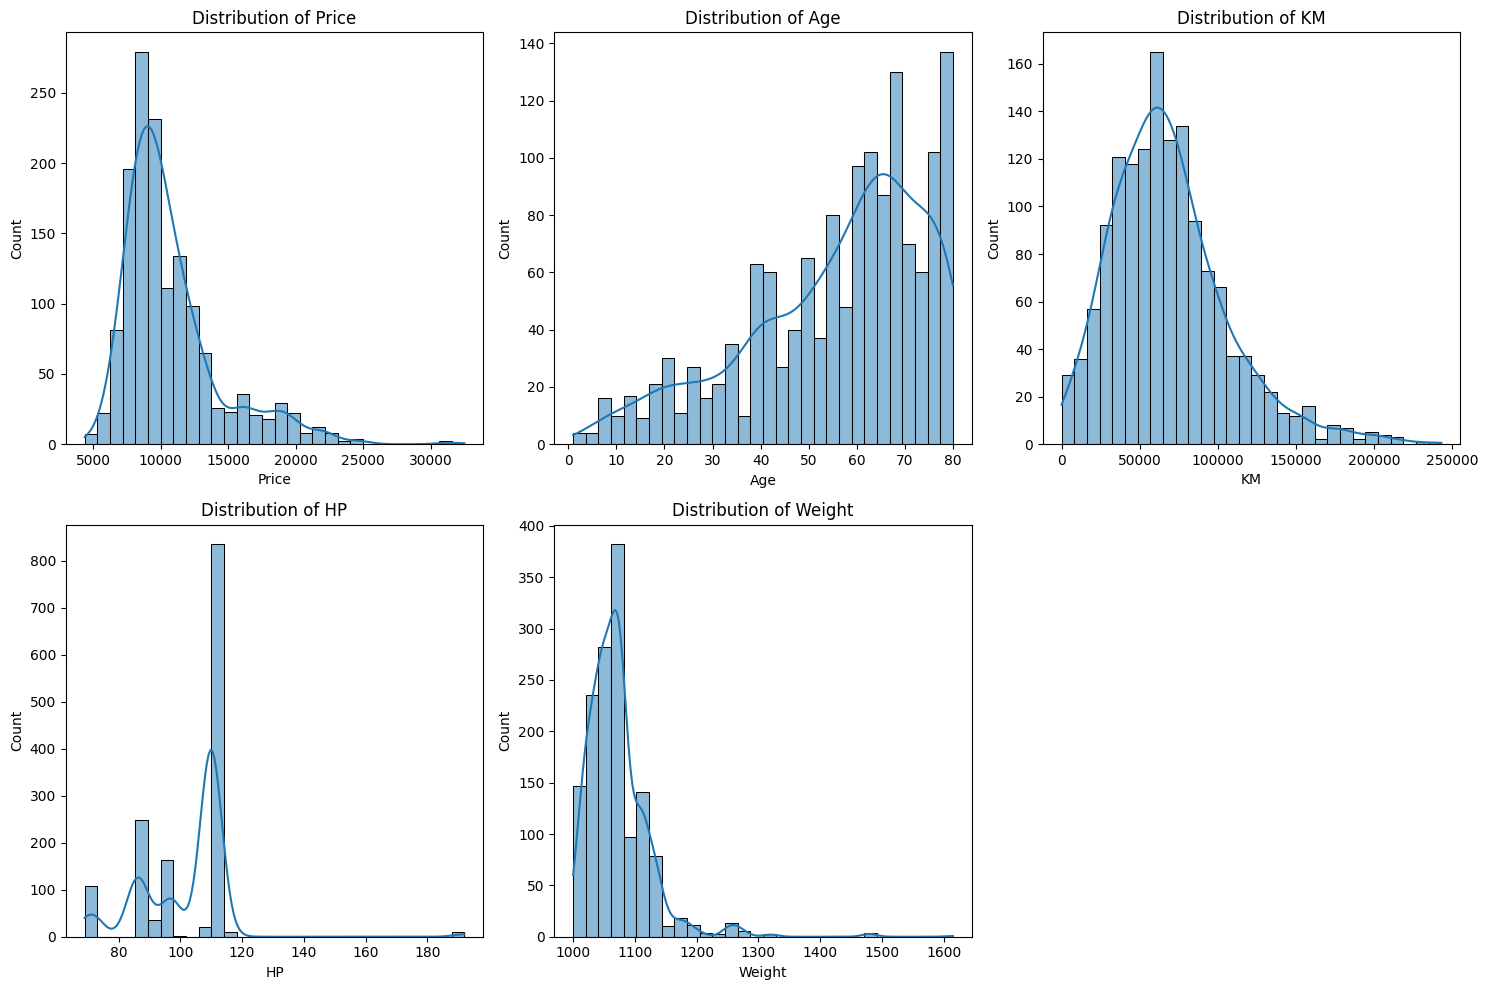

In [7]:
columns_to_plot = [c for c in ["Price", "Age", "KM", "HP", "Weight"] if c in df.columns]

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[column].dropna(), kde=True, bins=30)
    plt.title(f"Distribution of {column}")
plt.tight_layout()
plt.show()

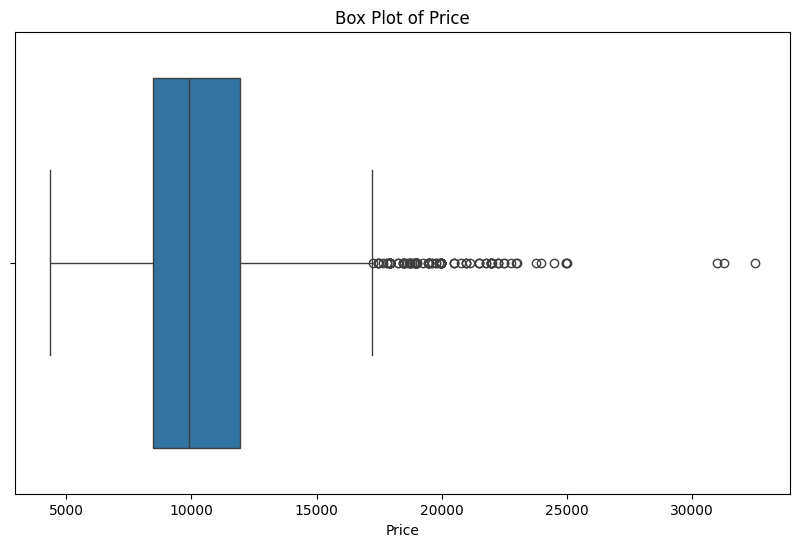

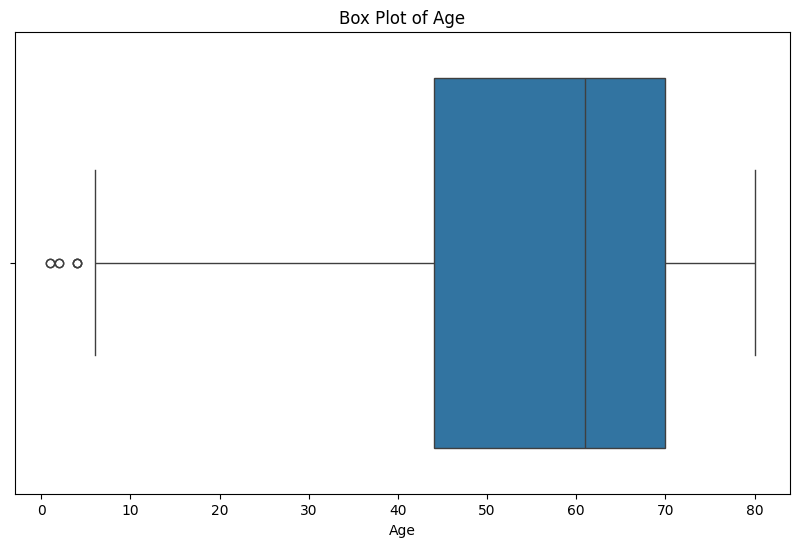

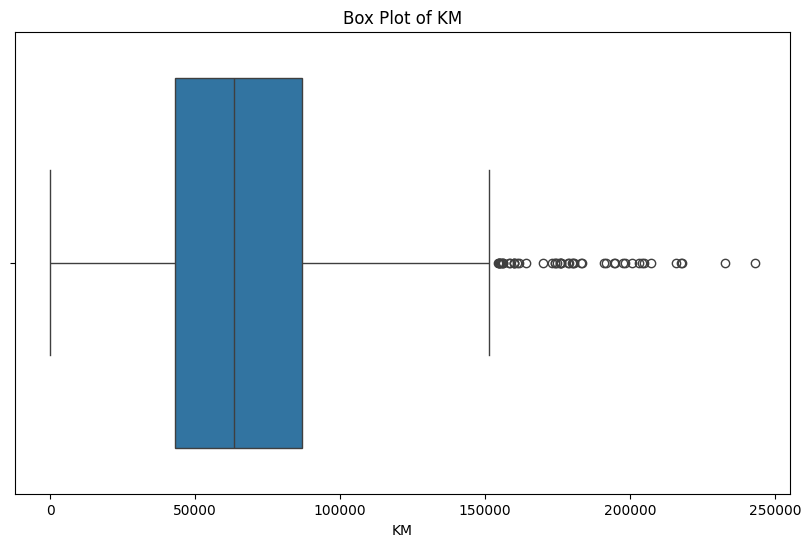

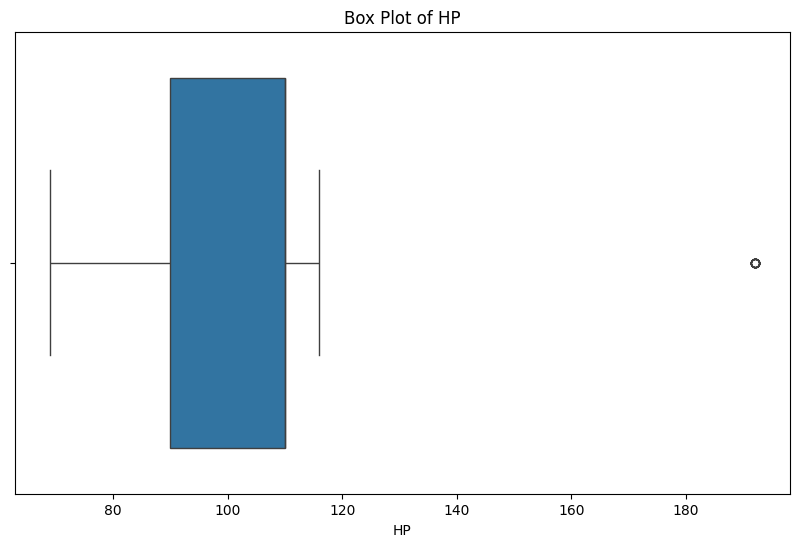

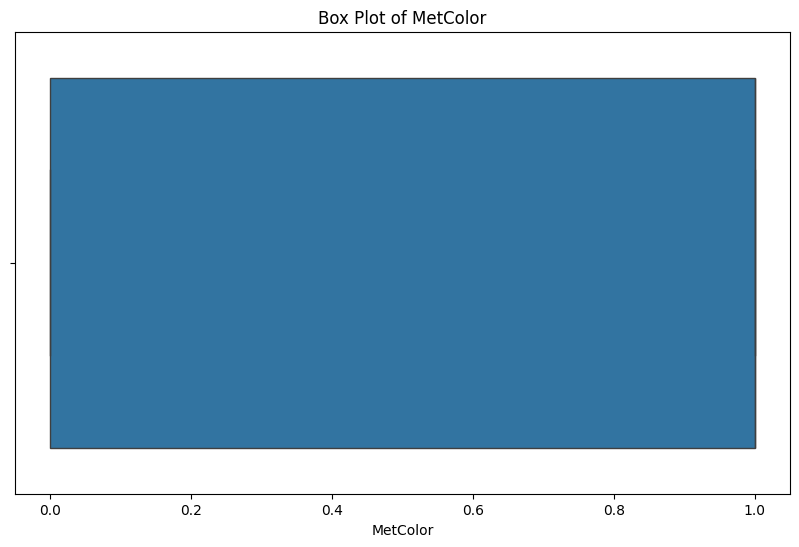

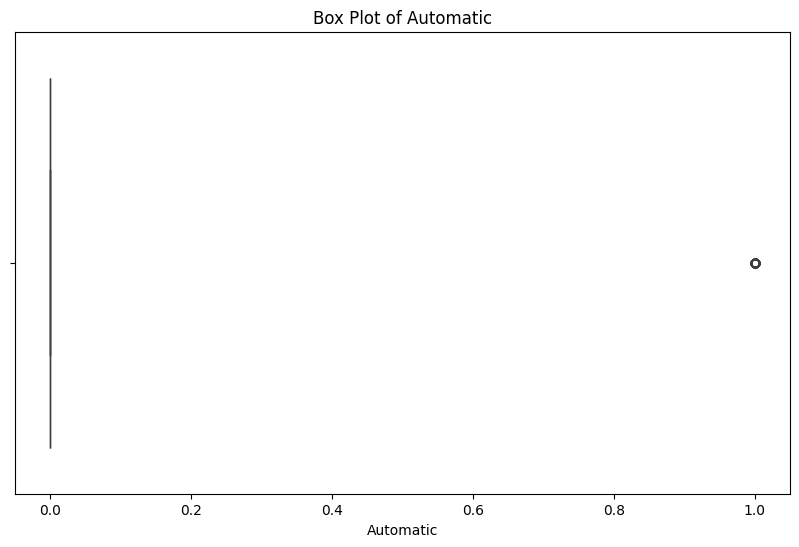

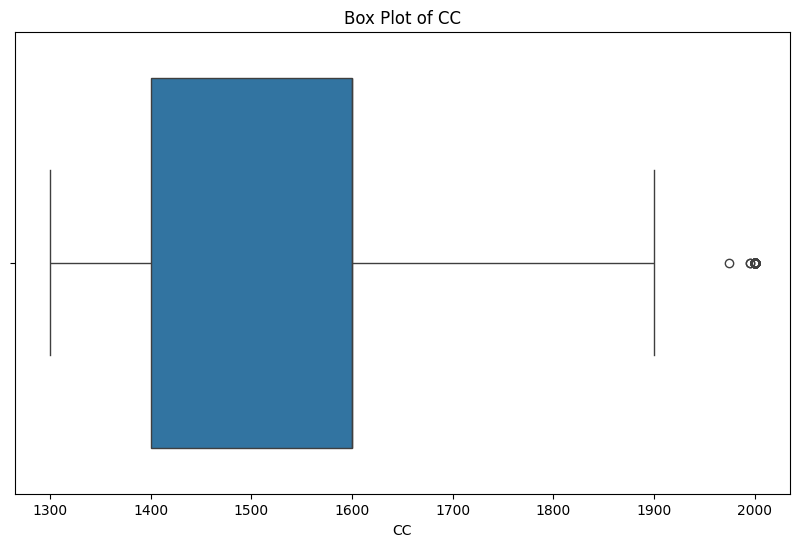

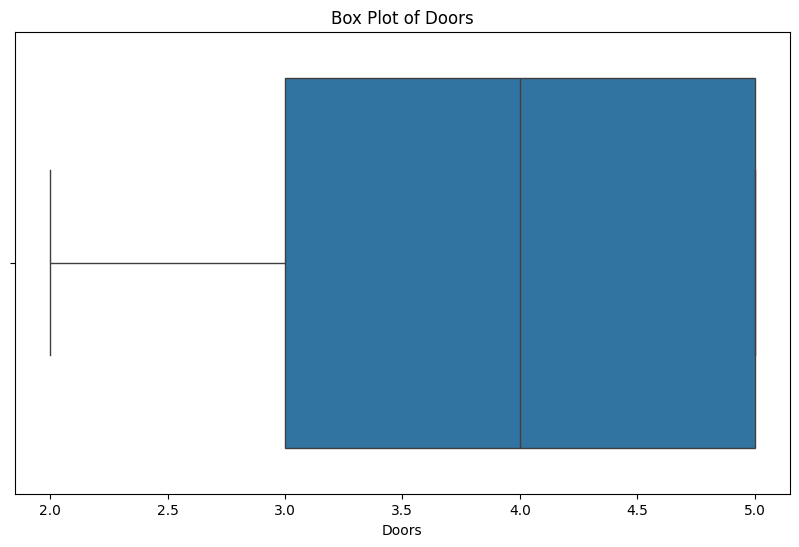

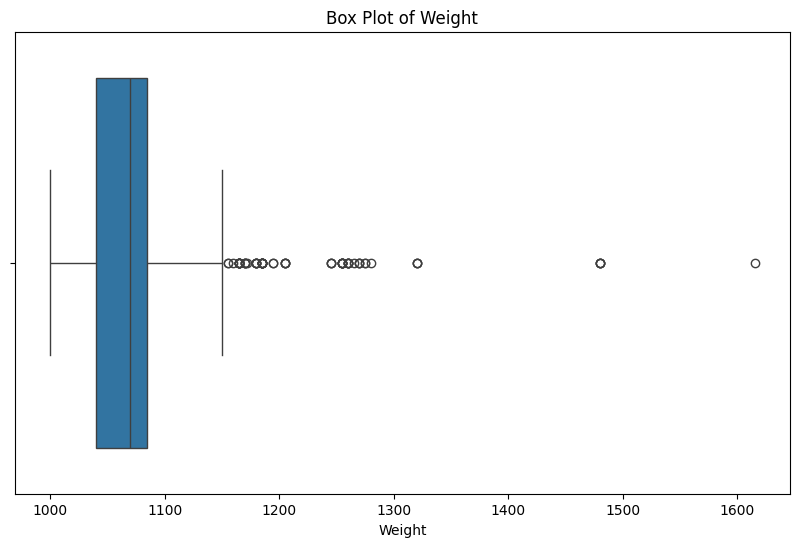

In [8]:
numeric_features = df.select_dtypes(include="number").columns

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f"Box Plot of {feature}")
    plt.show()

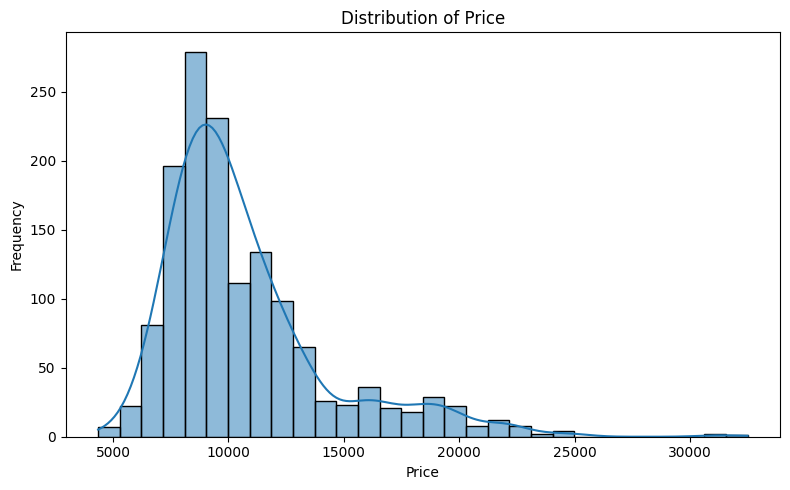

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Price"].dropna(), kde=True, bins=30)
plt.title("Distribution of Price")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

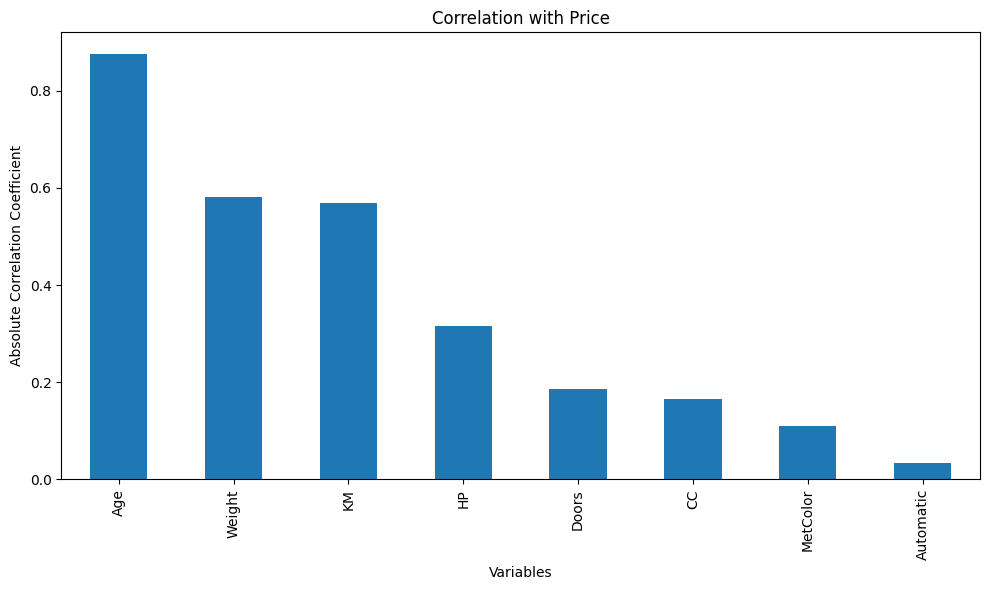

In [10]:
numeric_df = df.select_dtypes(include="number")

target_corr = numeric_df.corr()["Price"].drop("Price")
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

target_corr_sorted.plot(kind="bar", figsize=(10, 6))
plt.title("Correlation with Price")
plt.xlabel("Variables")
plt.ylabel("Absolute Correlation Coefficient")
plt.tight_layout()
plt.show()

## 3. Preprocessing

**3a. Filter outlier dengan IQR.** Sebuah baris dibuang jika ada satu saja nilai numerik di luar batas `Q1 - 1.5 x IQR` sampai `Q3 + 1.5 x IQR`.

> Catatan: kolom biner juga ikut diperiksa. Hanya sekitar 5,6% mobil yang otomatis, sehingga nilai 1 pada `Automatic` dianggap outlier. Akibatnya **semua mobil otomatis ikut terbuang** dan kolom `Automatic` menjadi 0 semua. Ini menjelaskan kenapa data turun dari 1436 menjadi 1133 baris.

**3b. Standardisasi.** Semua kolom numerik (termasuk `Price`) diubah ke rata-rata 0 dan simpangan baku 1. Karena `Price` ikut distandardisasi, nilai error pada evaluasi (MAE, RMSE) berada dalam satuan simpangan baku, bukan harga asli.

In [11]:
# 2. FILTER OUTLIER MENGGUNAKAN IQR
# Mempertahankan proses IQR sebelumnya
numeric_cols = df.select_dtypes(
    include="number"
).columns.tolist()

Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

condition = ~(
    (df[numeric_cols] < (Q1 - 1.5 * IQR)) |
    (df[numeric_cols] > (Q3 + 1.5 * IQR))
).any(axis=1)

df = df.loc[condition].copy()

print("\nUkuran dataset setelah IQR:", df.shape)


Ukuran dataset setelah IQR: (1133, 10)


In [12]:
scaler = StandardScaler()

df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

print("Standardisasi data berhasil.")
display(df.head())

Standardisasi data berhasil.


,Price,Age,KM,FuelType,HP,MetColor,Automatic,CC,Doors,Weight
9,1.250771,-2.327259,0.171083,Diesel,-3.090579,-1.450555,0.0,2.771355,-1.068359,1.699475
18,2.891764,-2.262058,-1.459682,Petrol,0.670468,-1.450555,0.0,0.572360,-1.068359,0.288254
19,2.978132,-1.870853,-0.071484,Petrol,0.670468,0.689391,0.0,0.572360,-1.068359,1.699475
20,2.546292,-1.870853,0.046633,Petrol,0.670468,0.689391,0.0,0.572360,-1.068359,1.699475
22,2.546292,-2.001255,-0.358098,Petrol,0.670468,0.689391,0.0,0.572360,-1.068359,2.228683


## 4. EDA Setelah Preprocessing
Memeriksa hasil preprocessing: histogram sebelum dan sesudah standardisasi, duplikat, lalu korelasi antar variabel. `FuelType` di-*label encode* hanya untuk keperluan korelasi dan visualisasi di bagian ini. Untuk model, kategori diubah dengan `get_dummies` di bagian 5.

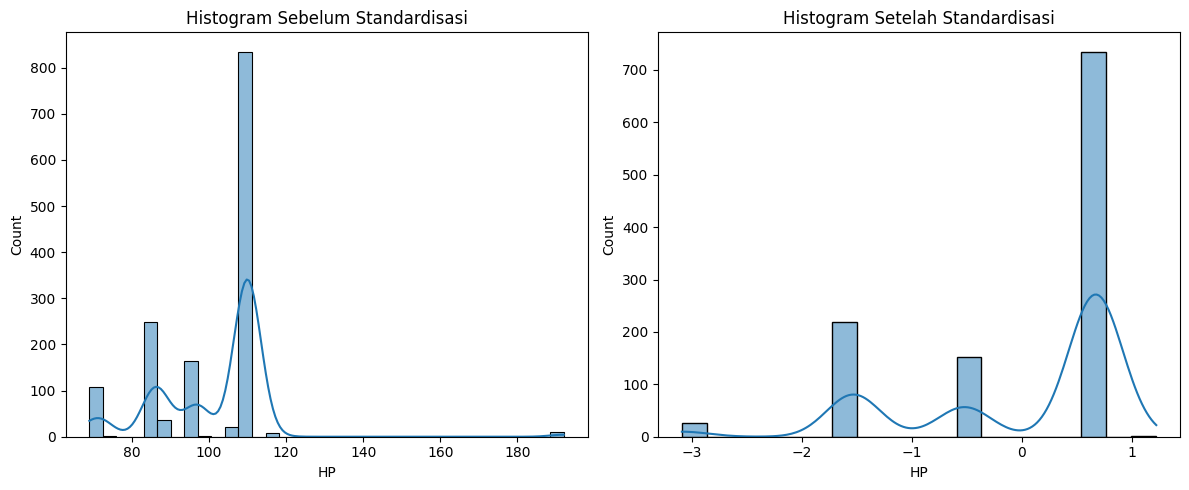

In [13]:
fitur_contoh = "HP"

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_awal[fitur_contoh], kde=True)
plt.title("Histogram Sebelum Standardisasi")

plt.subplot(1, 2, 2)
sns.histplot(df[fitur_contoh], kde=True)
plt.title("Histogram Setelah Standardisasi")

plt.tight_layout()
plt.show()

In [14]:
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Price, Age, KM, FuelType, HP, MetColor, Automatic, CC, Doors, Weight]
Index: []


In [15]:
category_features = df.select_dtypes(exclude="number").columns

label_encoder = LabelEncoder()
df_lencoder = df.copy()
for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

display(df_lencoder.head())

,Price,Age,KM,FuelType,HP,MetColor,Automatic,CC,Doors,Weight
9,1.250771,-2.327259,0.171083,1,-3.090579,-1.450555,0.0,2.771355,-1.068359,1.699475
18,2.891764,-2.262058,-1.459682,2,0.670468,-1.450555,0.0,0.572360,-1.068359,0.288254
19,2.978132,-1.870853,-0.071484,2,0.670468,0.689391,0.0,0.572360,-1.068359,1.699475
20,2.546292,-1.870853,0.046633,2,0.670468,0.689391,0.0,0.572360,-1.068359,1.699475
22,2.546292,-2.001255,-0.358098,2,0.670468,0.689391,0.0,0.572360,-1.068359,2.228683


In [16]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
}).sort_values(by="Missing Values", ascending=False)

display(missing_data[missing_data["Missing Values"] > 0])

,Missing Values,Percentage


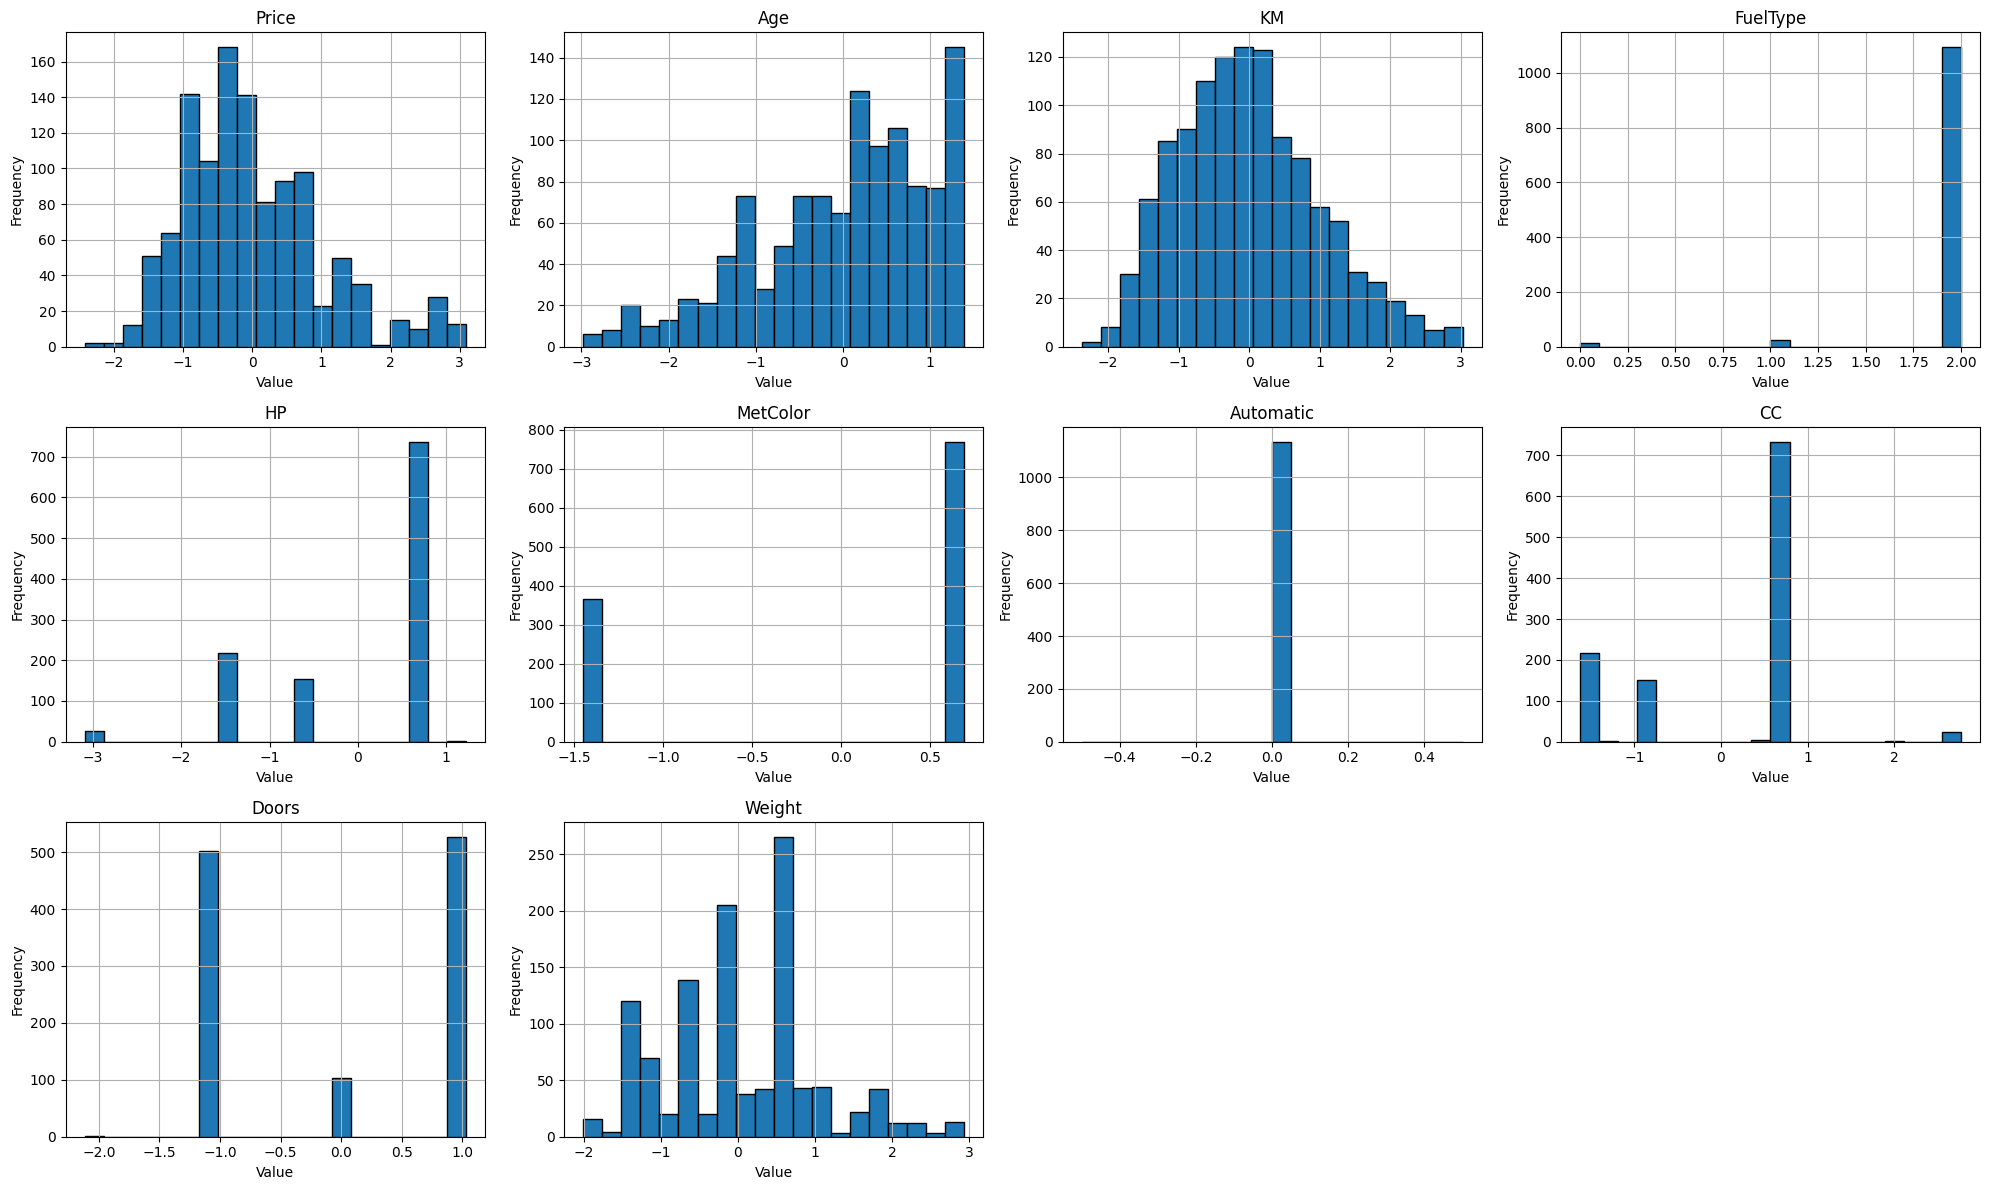

In [17]:
num_vars = df_lencoder.shape[1]
n_cols = 4
n_rows = -(-num_vars // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor="black")
    axes[i].set_title(column)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

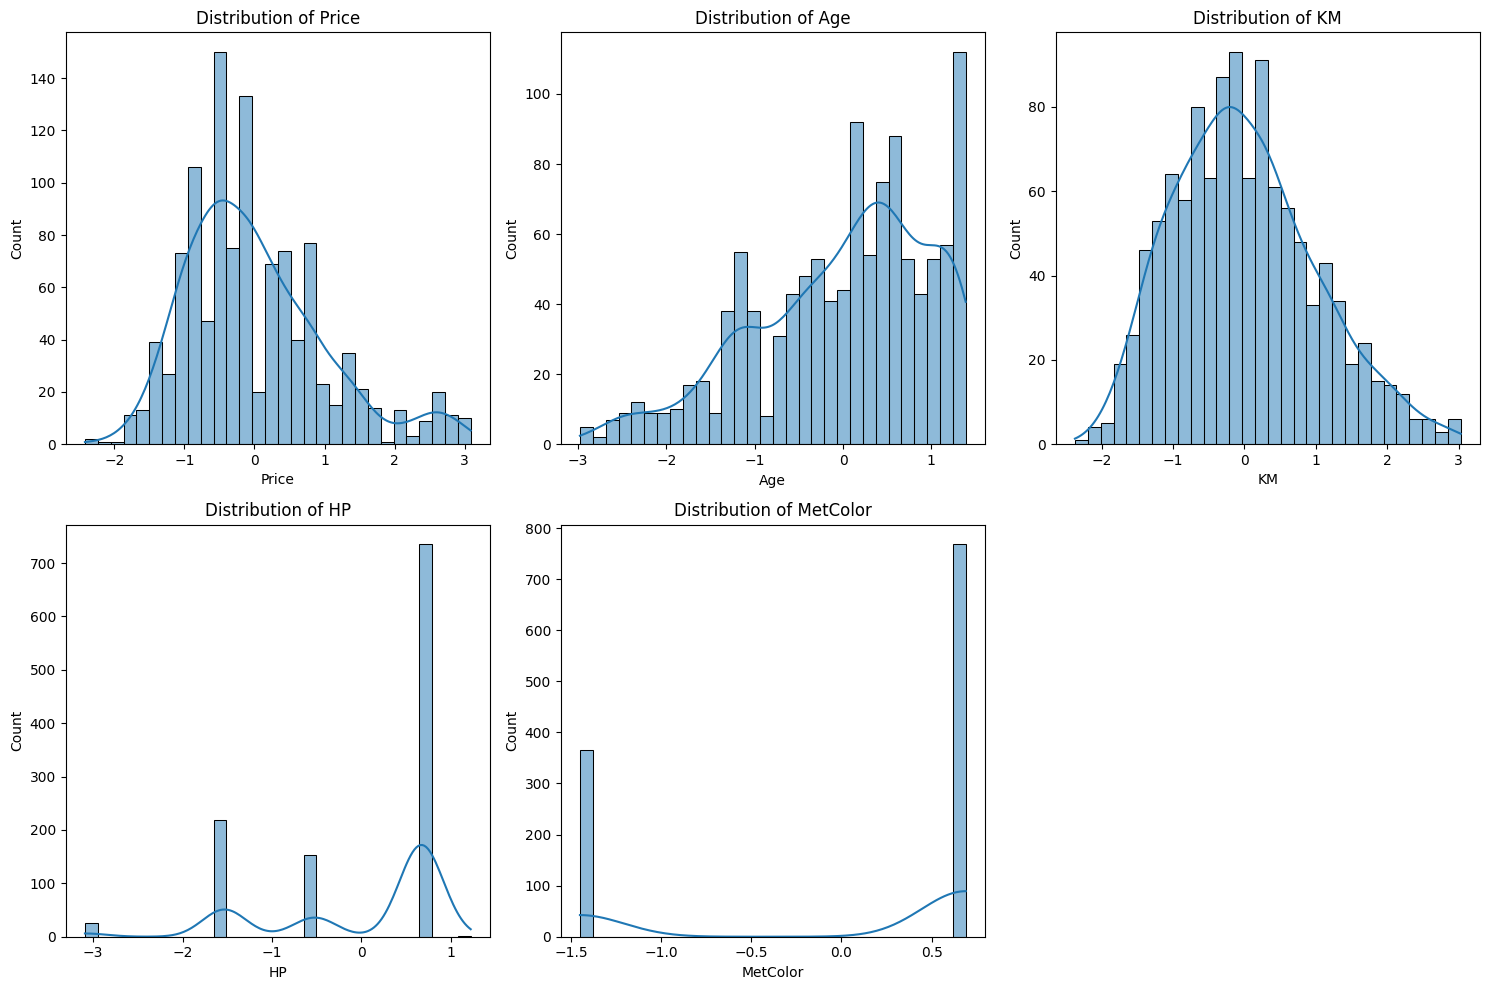

In [18]:
columns_to_plot = df.select_dtypes(include="number").columns[:5]

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[column].dropna(), kde=True, bins=30)
    plt.title(f"Distribution of {column}")
plt.tight_layout()
plt.show()

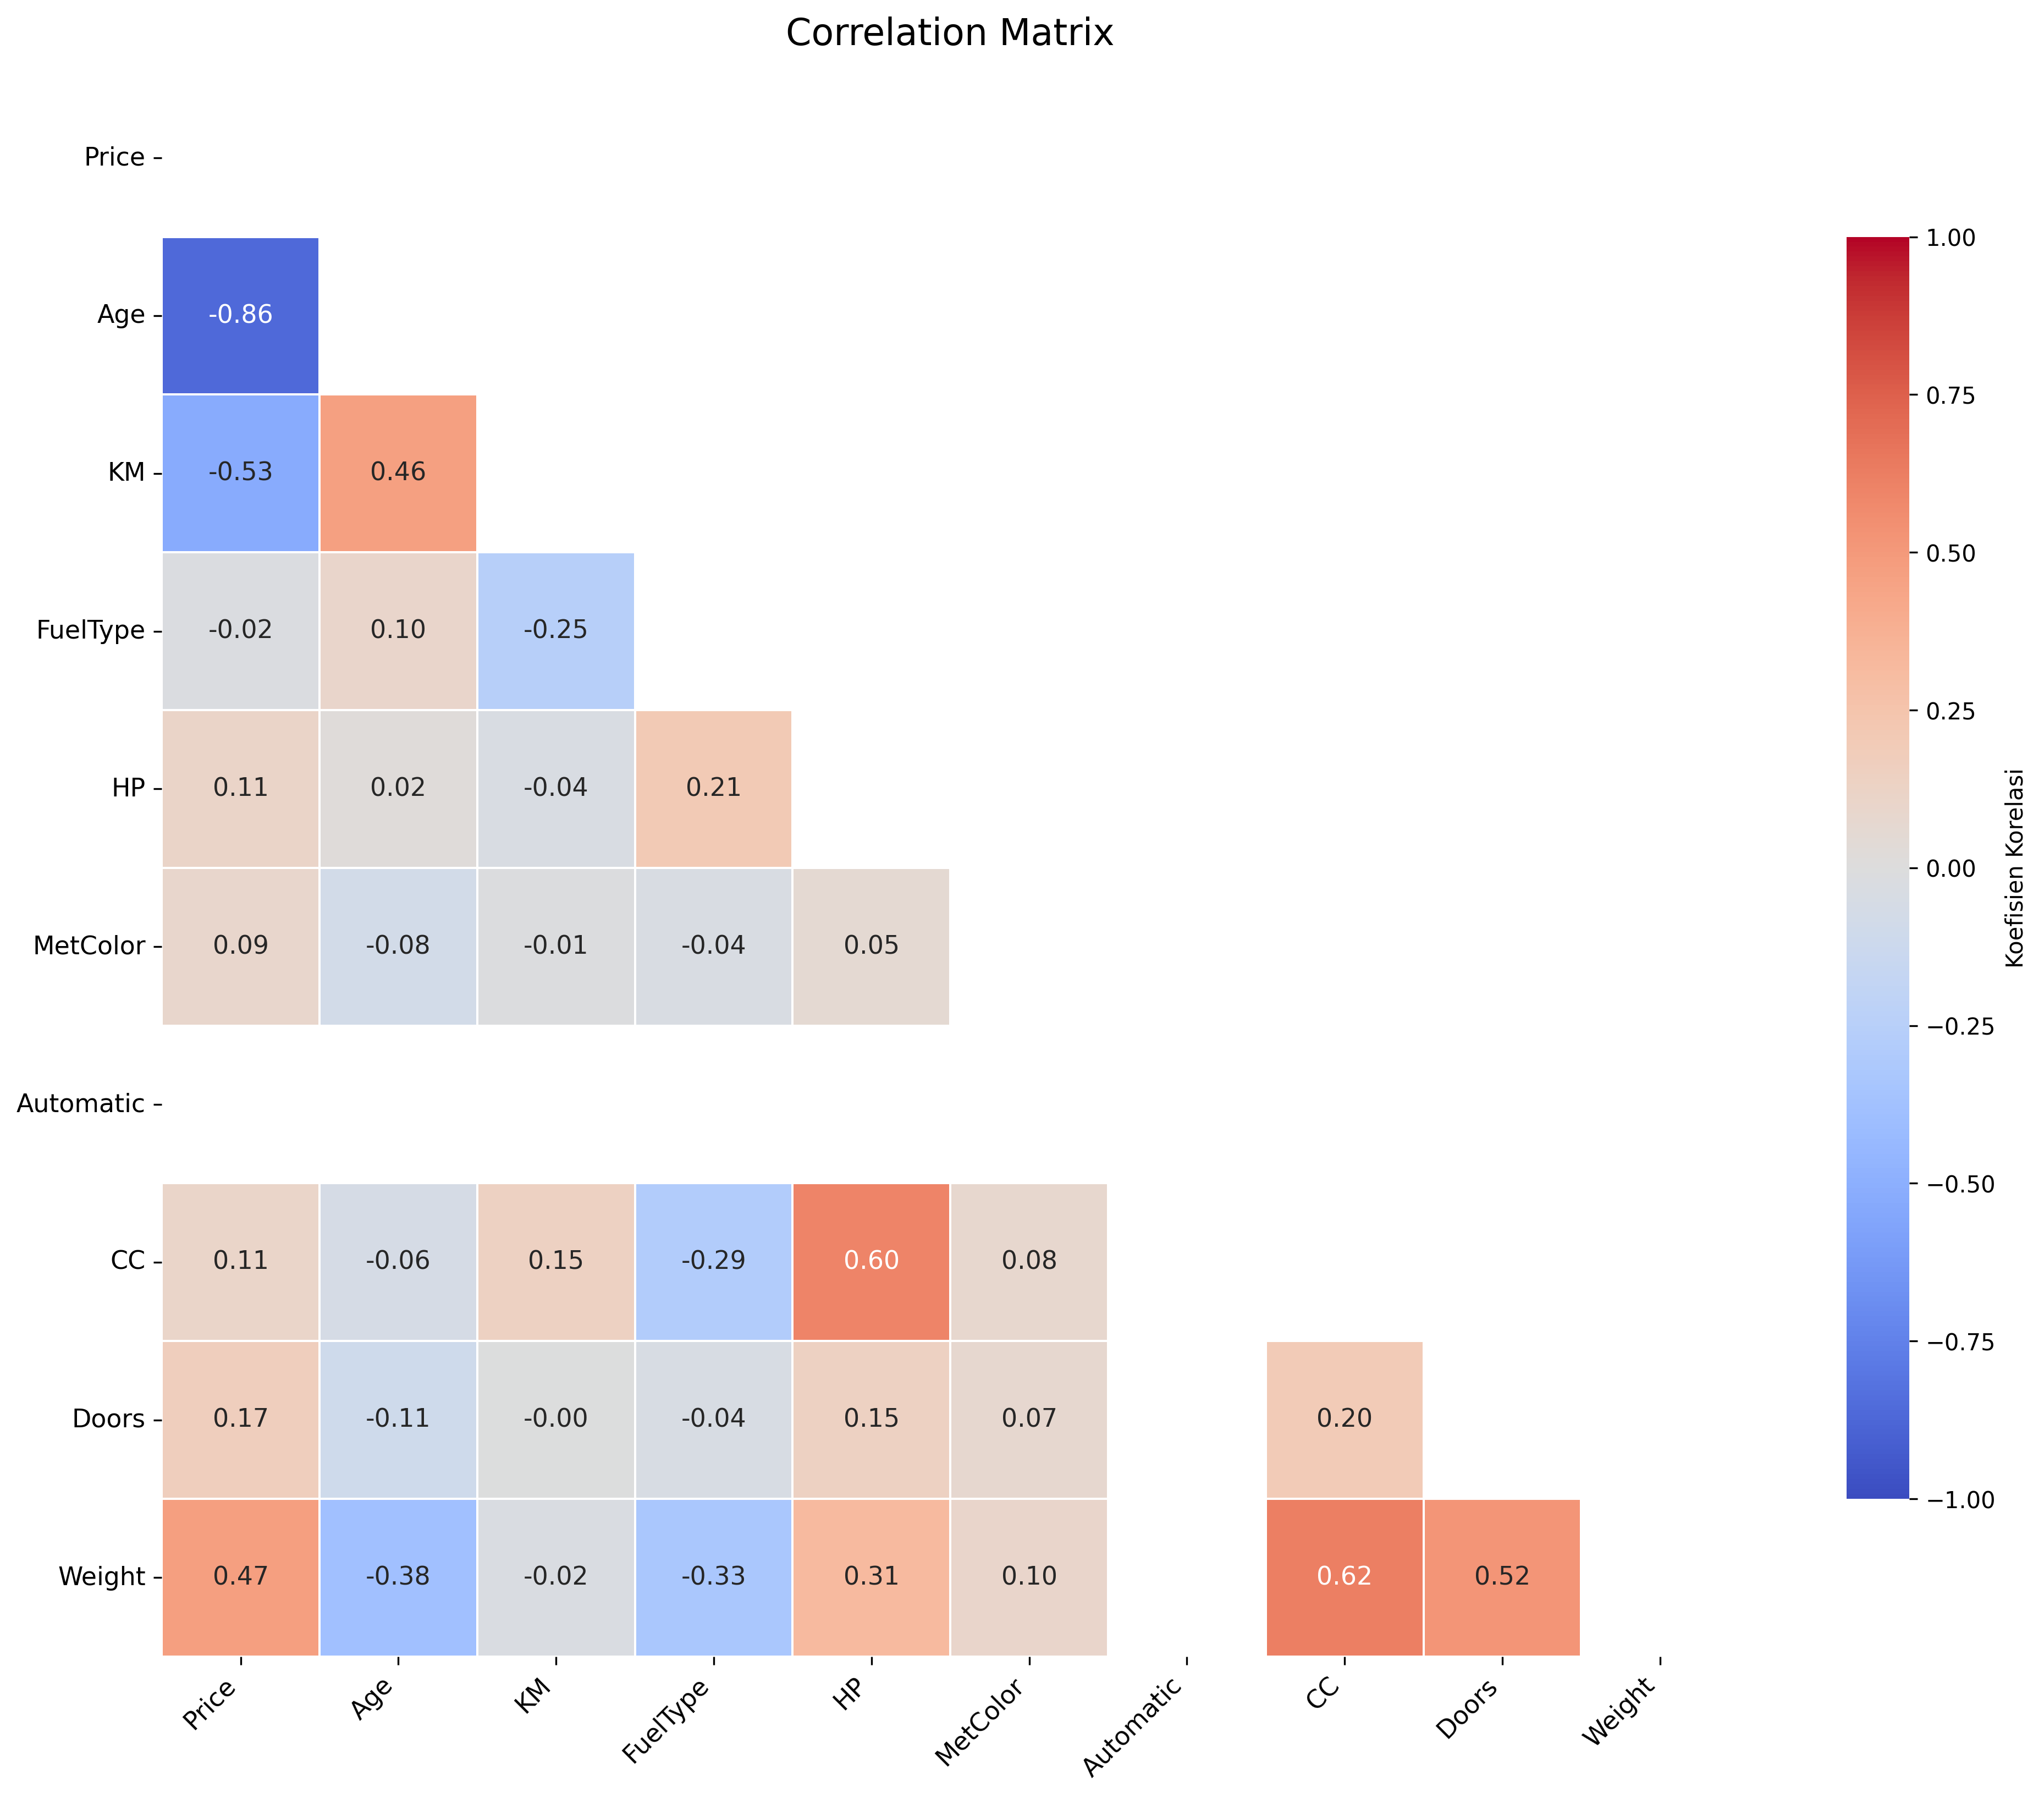

In [19]:
%config InlineBackend.figure_format = "retina"

correlation_matrix = df_lencoder.corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

plt.figure(figsize=(14, 11), dpi=150)

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,            # tampilkan angka korelasi
    fmt=".2f",             # 2 angka di belakang koma
    annot_kws={"size": 11},
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,        # garis pemisah antar kotak
    linecolor="white",
    square=True,
    cbar_kws={"shrink": 0.8, "label": "Koefisien Korelasi"}
)

plt.title("Correlation Matrix", fontsize=16, pad=15)
plt.xticks(rotation=45, ha="right", fontsize=11)
plt.yticks(rotation=0, fontsize=11)
plt.tight_layout()
plt.show()

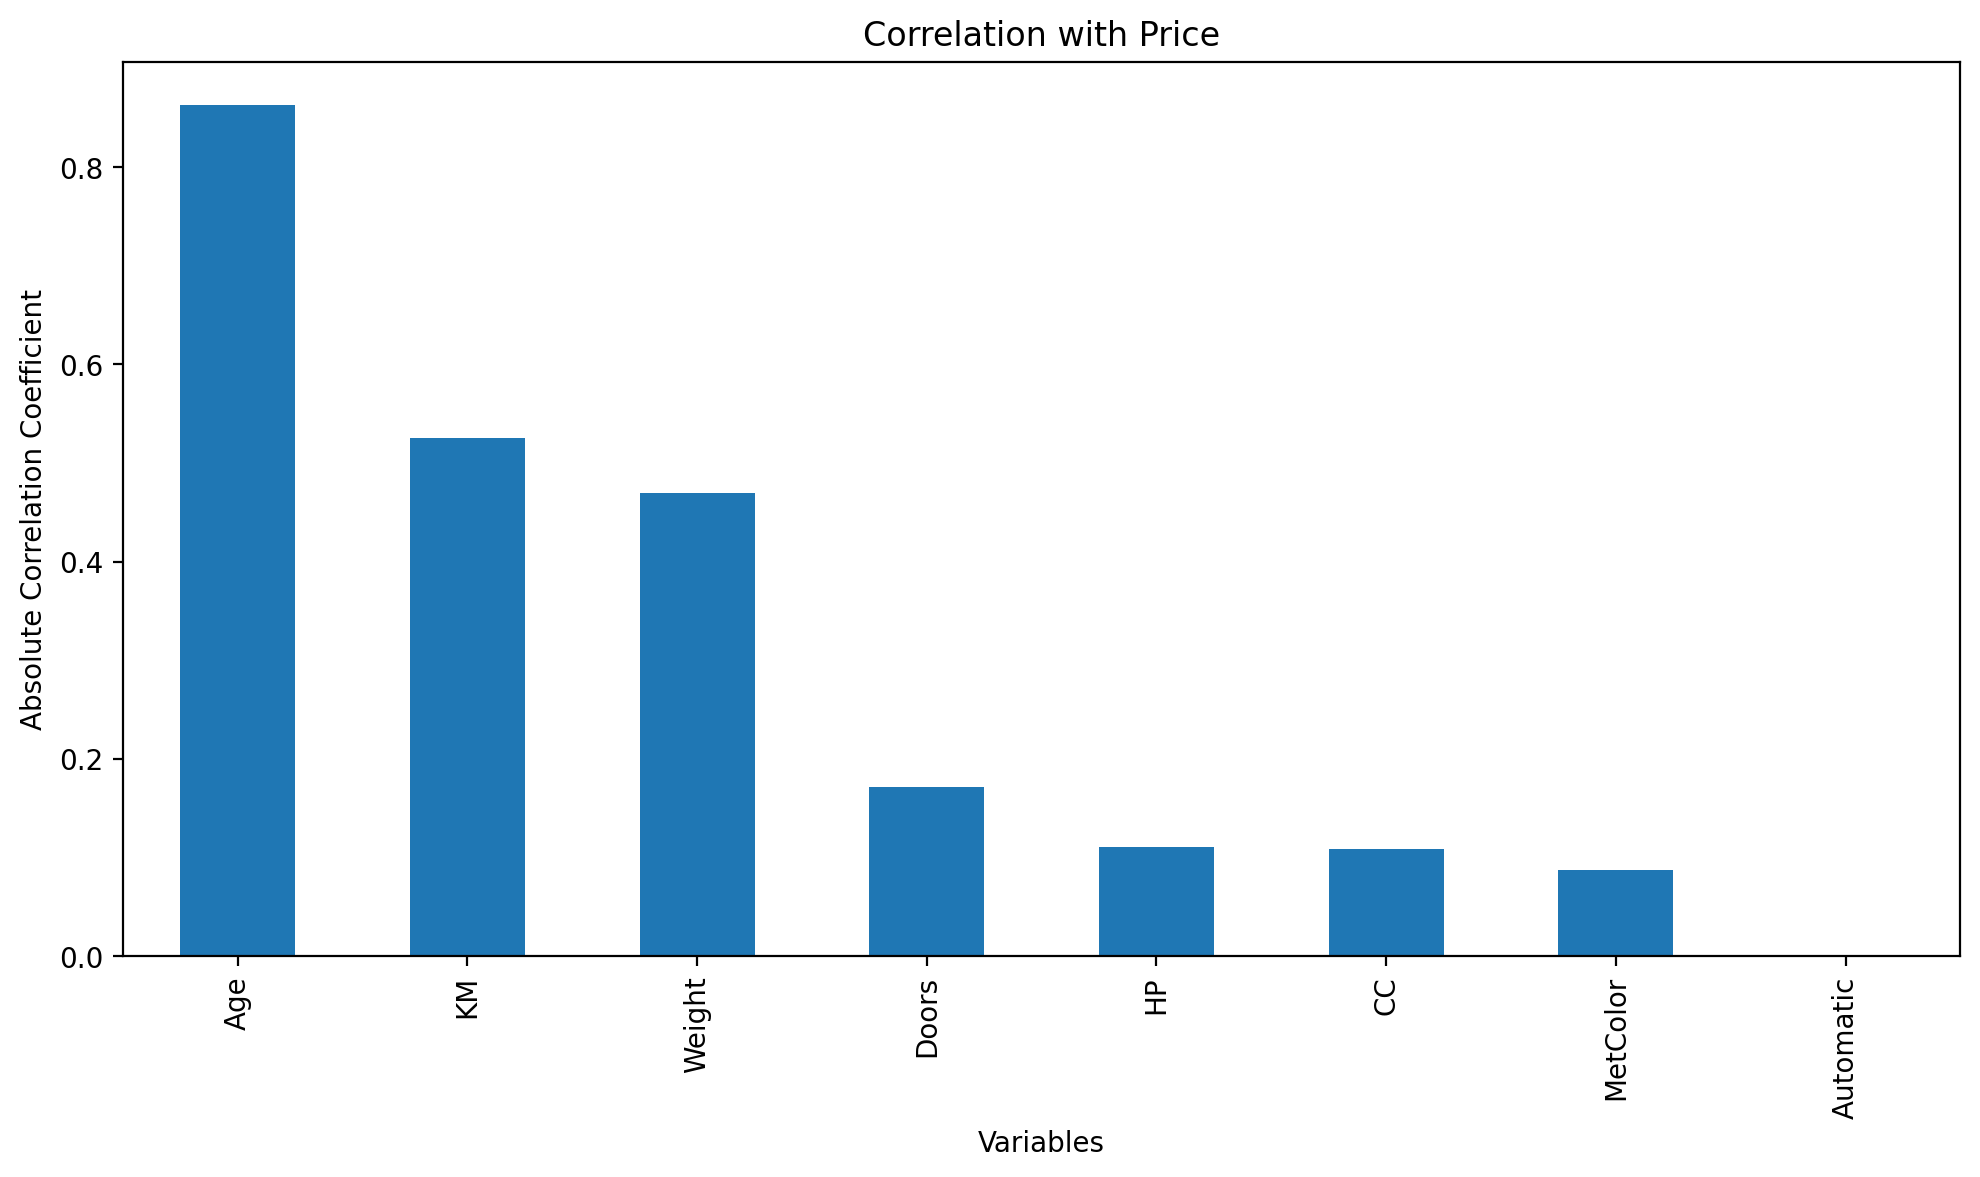

In [20]:
numeric_df = df.select_dtypes(include="number")

target_corr = numeric_df.corr()["Price"].drop("Price")
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind="bar")
plt.title("Correlation with Price")
plt.xlabel("Variables")
plt.ylabel("Absolute Correlation Coefficient")
plt.tight_layout()
plt.show()

## 5. Memisahkan Fitur/Target dan Membagi Data
- `X` = semua kolom kecuali `Price`; `y` = `Price`.
- `FuelType` diubah jadi kolom 0/1 dengan `get_dummies(drop_first=True)`, sehingga muncul `FuelType_Diesel` dan `FuelType_Petrol` (CNG menjadi pembanding).
- Data dibagi 80% training dan 20% testing dengan `random_state=42` supaya hasilnya selalu sama.

In [21]:
# 4. MEMISAHKAN FITUR DAN TARGET
df.columns = df.columns.str.strip()

X = df.drop(columns=["Price"])
y = df["Price"]

# Mengubah fitur kategorikal menjadi numerik
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)
# Menangani nilai tak hingga dan missing value
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

In [22]:
print("\nJumlah data:", len(X))
print("Jumlah fitur:", X.shape[1])
print("Missing value X:", X.isnull().sum().sum())
print("Kolom nonnumerik:", X.select_dtypes(
    exclude="number"
).columns.tolist())


Jumlah data: 1133
Jumlah fitur: 10
Missing value X: 0
Kolom nonnumerik: []


In [23]:
# 5. MEMBAGI DATA TRAINING DAN TESTING
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [24]:
print("\nUkuran X training:", x_train.shape)
print("Ukuran X testing:", x_test.shape)
print("Jumlah data training:", len(x_train))
print("Jumlah data testing:", len(x_test))


Ukuran X training: (906, 10)
Ukuran X testing: (227, 10)
Jumlah data training: 906
Jumlah data testing: 227


## 6. Melatih Tiga Model
| Model | Gambaran singkat |
|---|---|
| Gradient Boosting Regressor | Gabungan banyak pohon keputusan yang saling memperbaiki; mampu menangkap pola tidak linear |
| LARS (`n_nonzero_coefs=1`) | Model linear yang hanya diizinkan memakai **satu** fitur, sehingga sengaja menjadi pembanding sederhana |
| Linear Regression | Model linear klasik dengan semua fitur |

In [25]:
# 6. MELATIH MODEL REGRESI
GBR = GradientBoostingRegressor(
    random_state=184
)

GBR.fit(x_train, y_train)

print("\nModel regresi berhasil dilatih.")
print("Algoritma: Gradient Boosting Regressor")


Model regresi berhasil dilatih.
Algoritma: Gradient Boosting Regressor


In [26]:
lars = linear_model.Lars(n_nonzero_coefs=1)
lars.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"verbose verbose: bool or int, default=FalseSets the verbosity amount.",False
,"precompute precompute: bool, 'auto' or array-like , default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"n_nonzero_coefs n_nonzero_coefs: int, default=500Target number of non-zero coefficients. Use ``np.inf`` for no limit.",1
,"eps eps: float, default=np.finfo(float).epsThe machine-precision regularization in the computation of theCholesky diagonal factors. Increase this for very ill-conditionedsystems. Unlike the ``tol`` parameter in some iterativeoptimization-based algorithms, this parameter does not controlthe tolerance of the optimization.",np.float64(2....049250313e-16)
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"fit_path fit_path: bool, default=TrueIf True the full path is stored in the ``coef_path_`` attribute.If you compute the solution for a large problem or many targets,setting ``fit_path`` to ``False`` will lead to a speedup, especiallywith a small alpha.",True
,"jitter jitter: float, default=NoneUpper bound on a uniform noise parameter to be added to the`y` values, to satisfy the model's assumption ofone-at-a-time computations. Might help with stability... versionadded:: 0.23",None
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for jittering. Pass an intfor reproducible output across multiple function calls.See :term:`Glossary `. Ignored if `jitter` is None... versionadded:: 0.23",None


In [27]:
LR = LinearRegression()
LR.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## 7. Evaluasi dan Perbandingan Model
Cara membaca metrik (dihitung pada data testing):
- **MAE**: rata-rata selisih absolut prediksi vs aktual. Makin kecil makin baik.
- **MSE**: rata-rata kuadrat selisih. Error besar dihukum lebih berat.
- **RMSE**: akar dari MSE, satuannya sama dengan target.
- **R2**: seberapa besar variasi harga yang dijelaskan model. 1 berarti sempurna, 0 berarti sama buruknya dengan menebak rata-rata.

Model terbaik dipilih otomatis berdasarkan **R2 tertinggi**.

In [28]:
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

df_results = pd.DataFrame(
    {
        "MAE": [mae_lars, mae_LR, mae_GBR],
        "MSE": [mse_lars, mse_LR, mse_GBR],
        "RMSE": [np.sqrt(mse_lars), np.sqrt(mse_LR), np.sqrt(mse_GBR)],
        "R2": [r2_lars, r2_LR, r2_GBR]
    },
    index=["LARS", "Linear Regression", "Gradient Boosting"]
)

print("\nHASIL EVALUASI KETIGA MODEL")
display(df_results)


HASIL EVALUASI KETIGA MODEL


,MAE,MSE,RMSE,R2
LARS,0.430727,0.323985,0.569196,0.683556
Linear Regression,0.339680,0.192689,0.438964,0.811796
Gradient Boosting,0.319636,0.170758,0.413229,0.833216


In [29]:
# 15. PERBANDINGAN PERFORMA MODEL (DIURUTKAN BERDASARKAN R2)
hasil_regresi = df_results.copy()

print("PERBANDINGAN PERFORMA MODEL REGRESI")
display(hasil_regresi.sort_values(by="R2", ascending=False).round(4))

model_terbaik = hasil_regresi["R2"].idxmax()
print("Model terbaik berdasarkan R2:", model_terbaik)

PERBANDINGAN PERFORMA MODEL REGRESI

,MAE,MSE,RMSE,R2
Gradient Boosting,0.3196,0.1708,0.4132,0.8332
Linear Regression,0.3397,0.1927,0.4390,0.8118
LARS,0.4307,0.3240,0.5692,0.6836


Model terbaik berdasarkan R2: Gradient Boosting


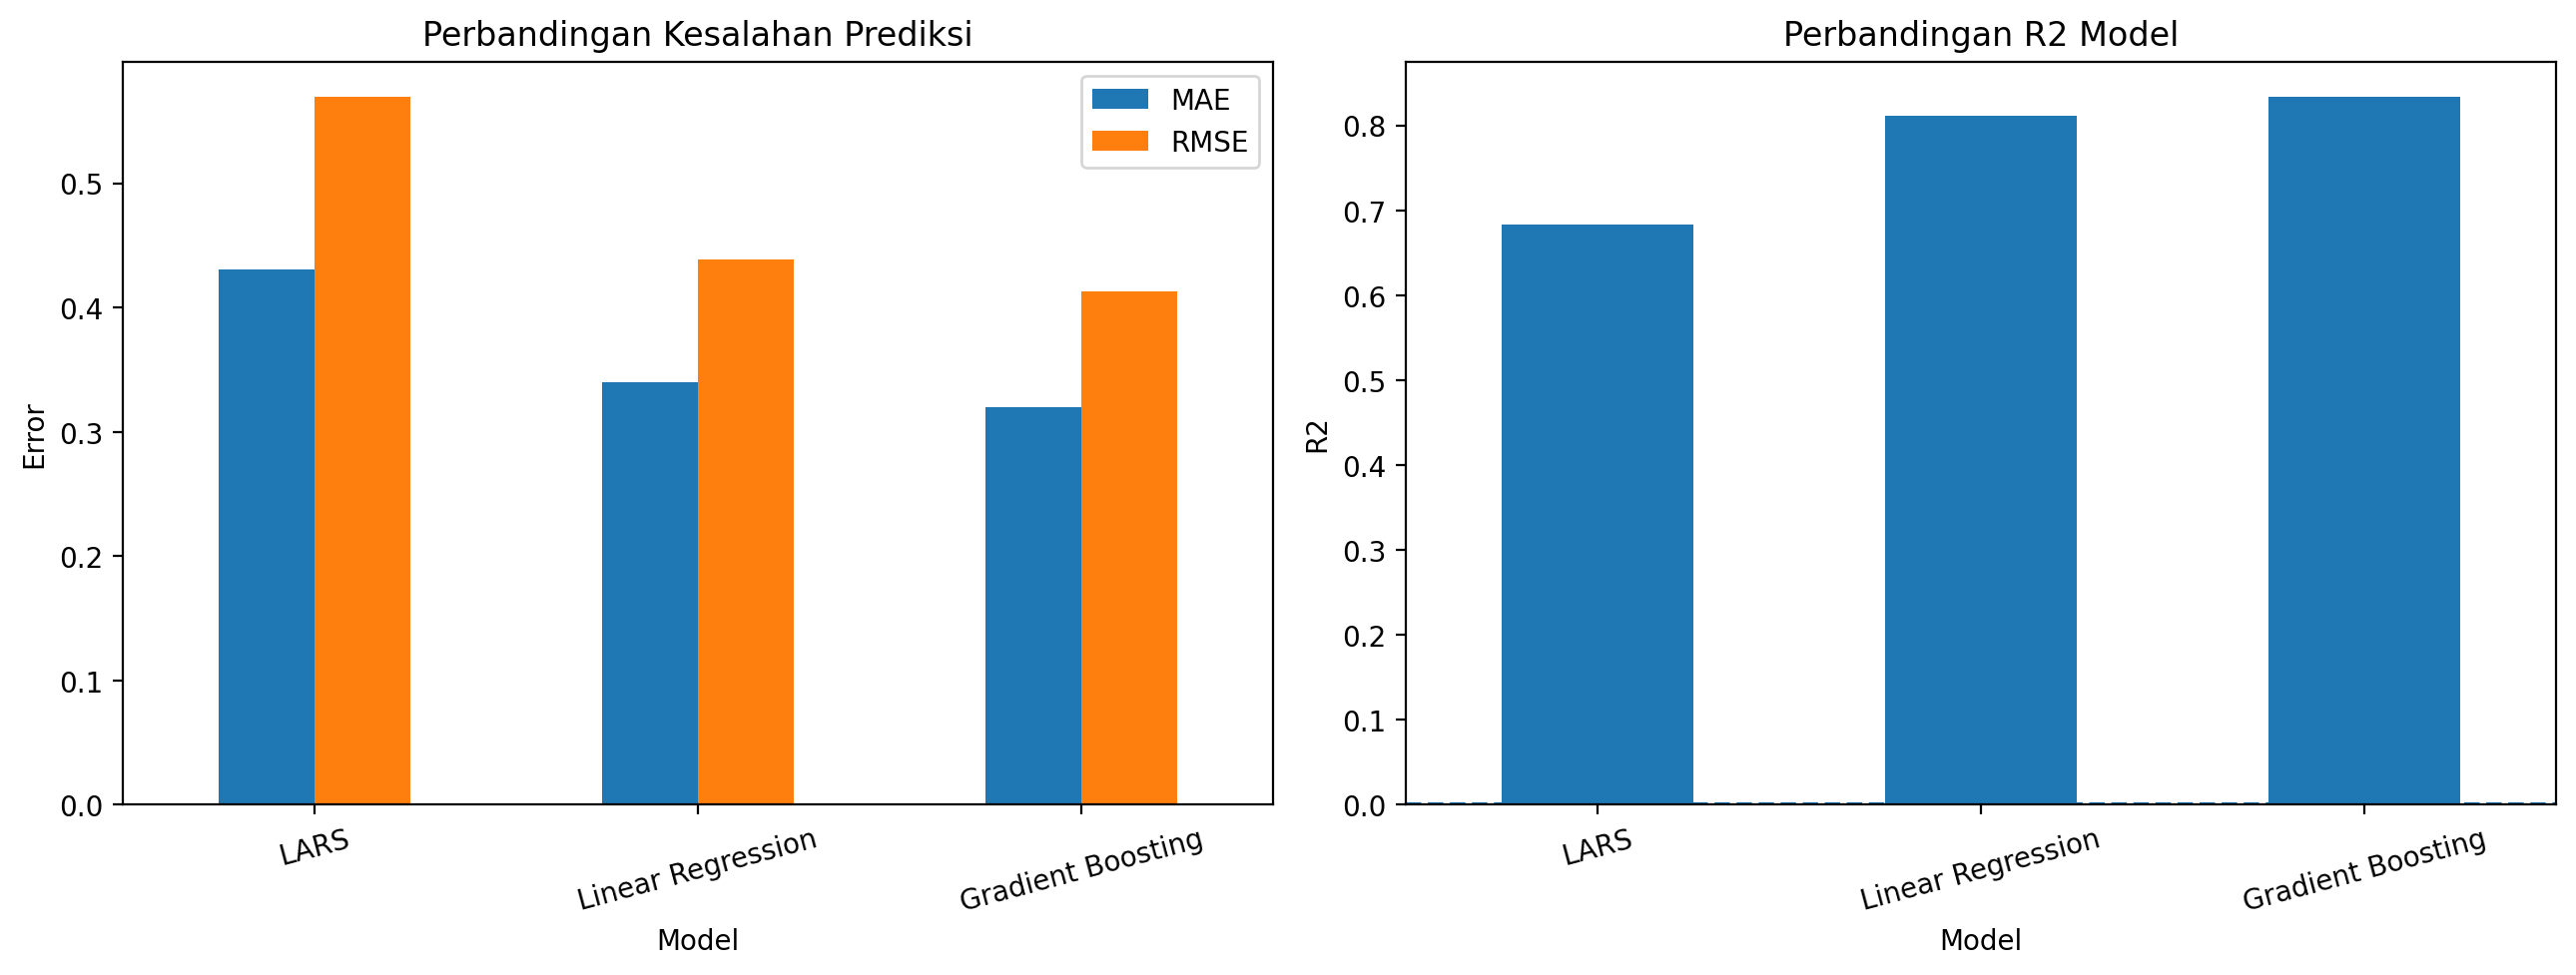

In [30]:
# 16. VISUALISASI PERBANDINGAN MODEL
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

hasil_regresi[["MAE", "RMSE"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Perbandingan Kesalahan Prediksi")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Error")
axes[0].tick_params(axis="x", rotation=15)

hasil_regresi["R2"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Perbandingan R2 Model")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("R2")
axes[1].axhline(y=0, linestyle="--")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

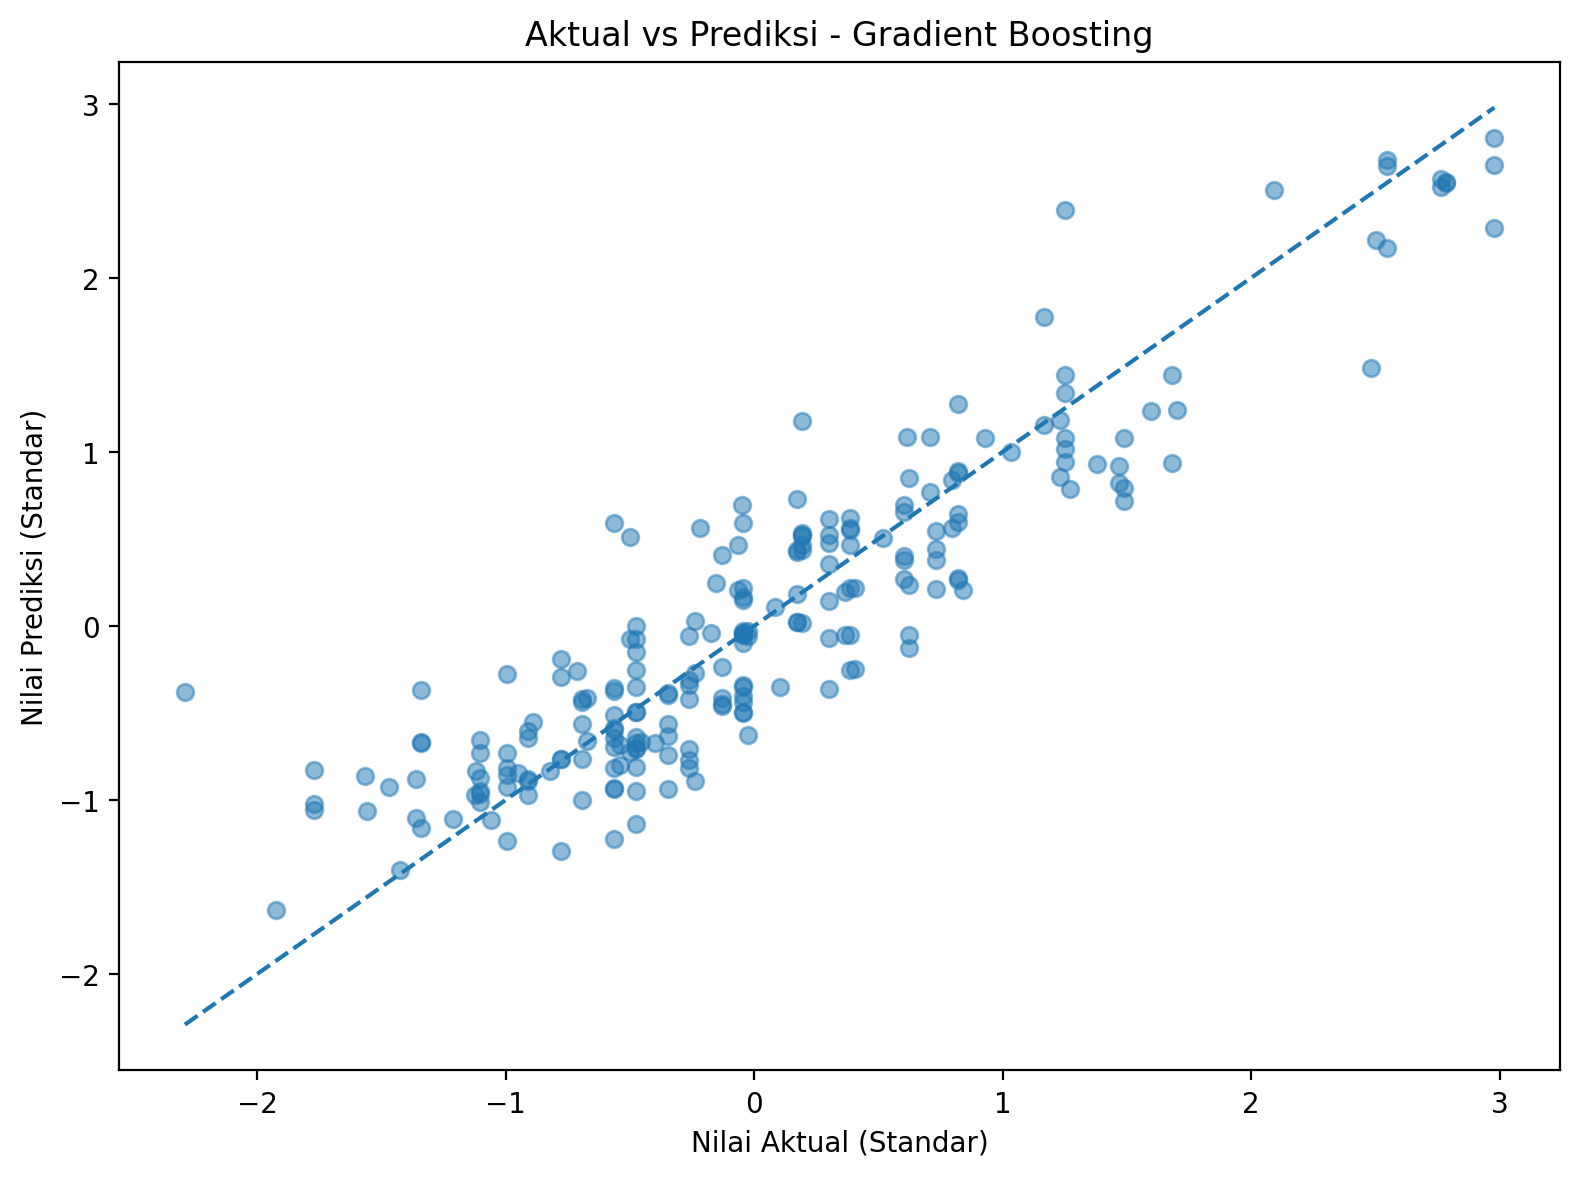

In [31]:
# 17. AKTUAL VS PREDIKSI - MODEL TERBAIK
model_lookup = {
    "LARS": lars,
    "Linear Regression": LR,
    "Gradient Boosting": GBR
}

best_model = model_lookup[model_terbaik]
prediksi_terbaik = best_model.predict(x_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, prediksi_terbaik, alpha=0.5)

batas_bawah = min(y_test.min(), prediksi_terbaik.min())
batas_atas = max(y_test.max(), prediksi_terbaik.max())

plt.plot([batas_bawah, batas_atas], [batas_bawah, batas_atas], linestyle="--")

plt.xlabel("Nilai Aktual (Standar)")
plt.ylabel("Nilai Prediksi (Standar)")
plt.title(f"Aktual vs Prediksi - {model_terbaik}")
plt.tight_layout()
plt.show()

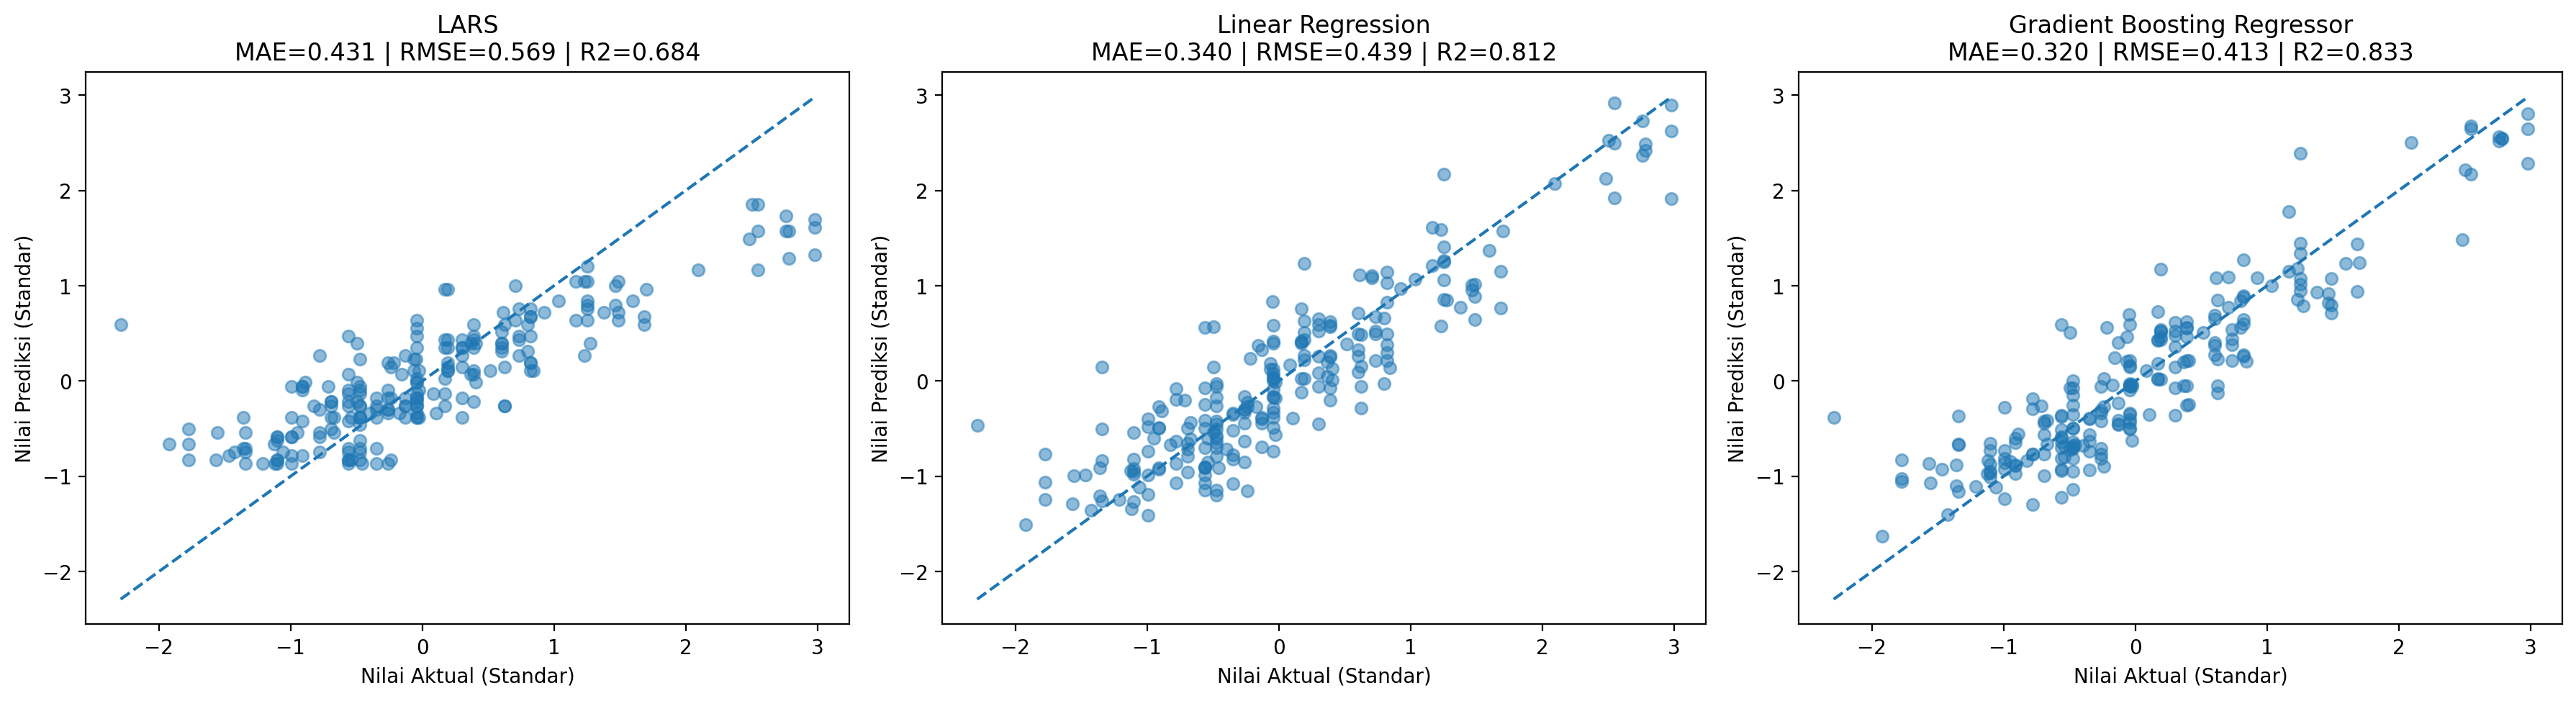

In [32]:
predictions_model = {
    "LARS": pred_lars,
    "Linear Regression": pred_LR,
    "Gradient Boosting Regressor": pred_GBR
}

y_actual = np.asarray(y_test).ravel()

all_values = np.concatenate(
    [y_actual] + [np.asarray(p).ravel() for p in predictions_model.values()]
)
lower = all_values.min()
upper = all_values.max()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nama_model, prediksi) in zip(axes, predictions_model.items()):
    prediksi = np.asarray(prediksi).ravel()

    mae_m = mean_absolute_error(y_actual, prediksi)
    rmse_m = np.sqrt(mean_squared_error(y_actual, prediksi))
    r2_m = r2_score(y_actual, prediksi)

    ax.scatter(y_actual, prediksi, alpha=0.5)
    ax.plot([lower, upper], [lower, upper], linestyle="--")
    ax.set_title(
        f"{nama_model}\n"
        f"MAE={mae_m:.3f} | RMSE={rmse_m:.3f} | R2={r2_m:.3f}"
    )
    ax.set_xlabel("Nilai Aktual (Standar)")
    ax.set_ylabel("Nilai Prediksi (Standar)")

plt.tight_layout()
plt.show()

In [33]:
urut = hasil_regresi.sort_values(by="R2", ascending=False)

print("KESIMPULAN EVALUASI")
print(f"Model terbaik : {model_terbaik}")
print(f"  MAE  = {urut.loc[model_terbaik, 'MAE']:.4f}")
print(f"  RMSE = {urut.loc[model_terbaik, 'RMSE']:.4f}")
print(f"  R2   = {urut.loc[model_terbaik, 'R2']:.4f}")
print("\nUrutan model berdasarkan R2:", " > ".join(urut.index))

KESIMPULAN EVALUASI
Model terbaik : Gradient Boosting
  MAE  = 0.3196
  RMSE = 0.4132
  R2   = 0.8332

Urutan model berdasarkan R2: Gradient Boosting > Linear Regression > LARS


## 8. Analisis Detail Gradient Boosting
- **Contoh prediksi dan residual.** Residual = nilai aktual dikurangi prediksi.
- **Plot residual.** Titik yang tersebar acak di sekitar garis 0 berarti model tidak punya kesalahan sistematis. Pola melengkung berarti ada pola yang terlewat.
- **Feature importance.** Fitur mana yang paling berpengaruh pada prediksi. Pada hasil di notebook ini, `Age` paling dominan.

In [34]:
# 7. MEMBUAT PREDIKSI
y_pred = GBR.predict(x_test)

hasil_prediksi = pd.DataFrame({
    "Nilai Aktual": y_test.to_numpy(),
    "Nilai Prediksi": y_pred
})

hasil_prediksi["Residual"] = (
    hasil_prediksi["Nilai Aktual"]
    - hasil_prediksi["Nilai Prediksi"]
)

print("\nContoh hasil prediksi:")
display(hasil_prediksi.head(10))


Contoh hasil prediksi:


,Nilai Aktual,Nilai Prediksi,Residual
0,-0.498182,-0.075356,-0.422826
1,-0.994798,-0.925478,-0.069321
2,0.387091,-0.049635,0.436726
3,-0.131118,-0.233573,0.102455
4,-0.044750,-0.095505,0.050755
5,1.034851,0.996911,0.037940
6,-0.562958,-0.357179,-0.205779
7,2.546292,2.644444,-0.098152
8,-0.476590,-0.674506,0.197916
9,-1.923255,-1.630984,-0.292271


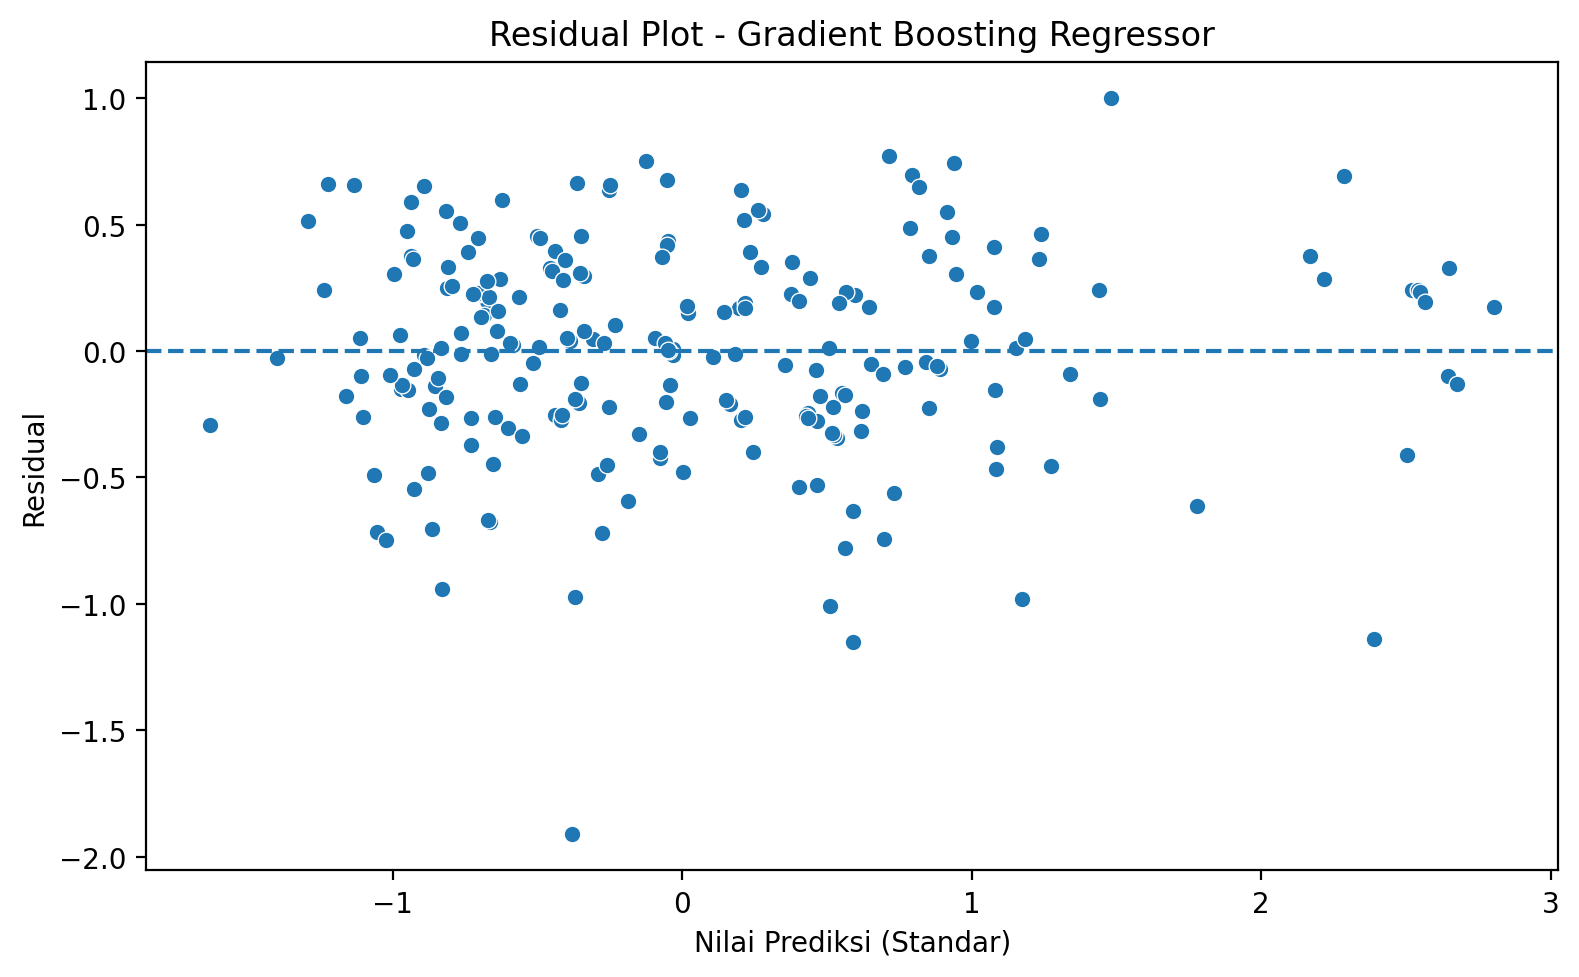

In [35]:
# 10. VISUALISASI RESIDUAL
residual = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred,
    y=residual
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Nilai Prediksi (Standar)")
plt.ylabel("Residual")
plt.title("Residual Plot - Gradient Boosting Regressor")

plt.tight_layout()
plt.show()

In [36]:
# 11. FEATURE IMPORTANCE
feature_importance = pd.Series(
    GBR.feature_importances_,
    index=x_train.columns
).sort_values(ascending=False)

print("\nFEATURE IMPORTANCE")
display(
    feature_importance.to_frame(
        name="Importance"
    ).round(4)
)


FEATURE IMPORTANCE


,Importance
Age,0.8735
KM,0.0596
Weight,0.0540
HP,0.0042
CC,0.0024
FuelType_Diesel,0.0018
MetColor,0.0016
Doors,0.0015
FuelType_Petrol,0.0015
Automatic,0.0000


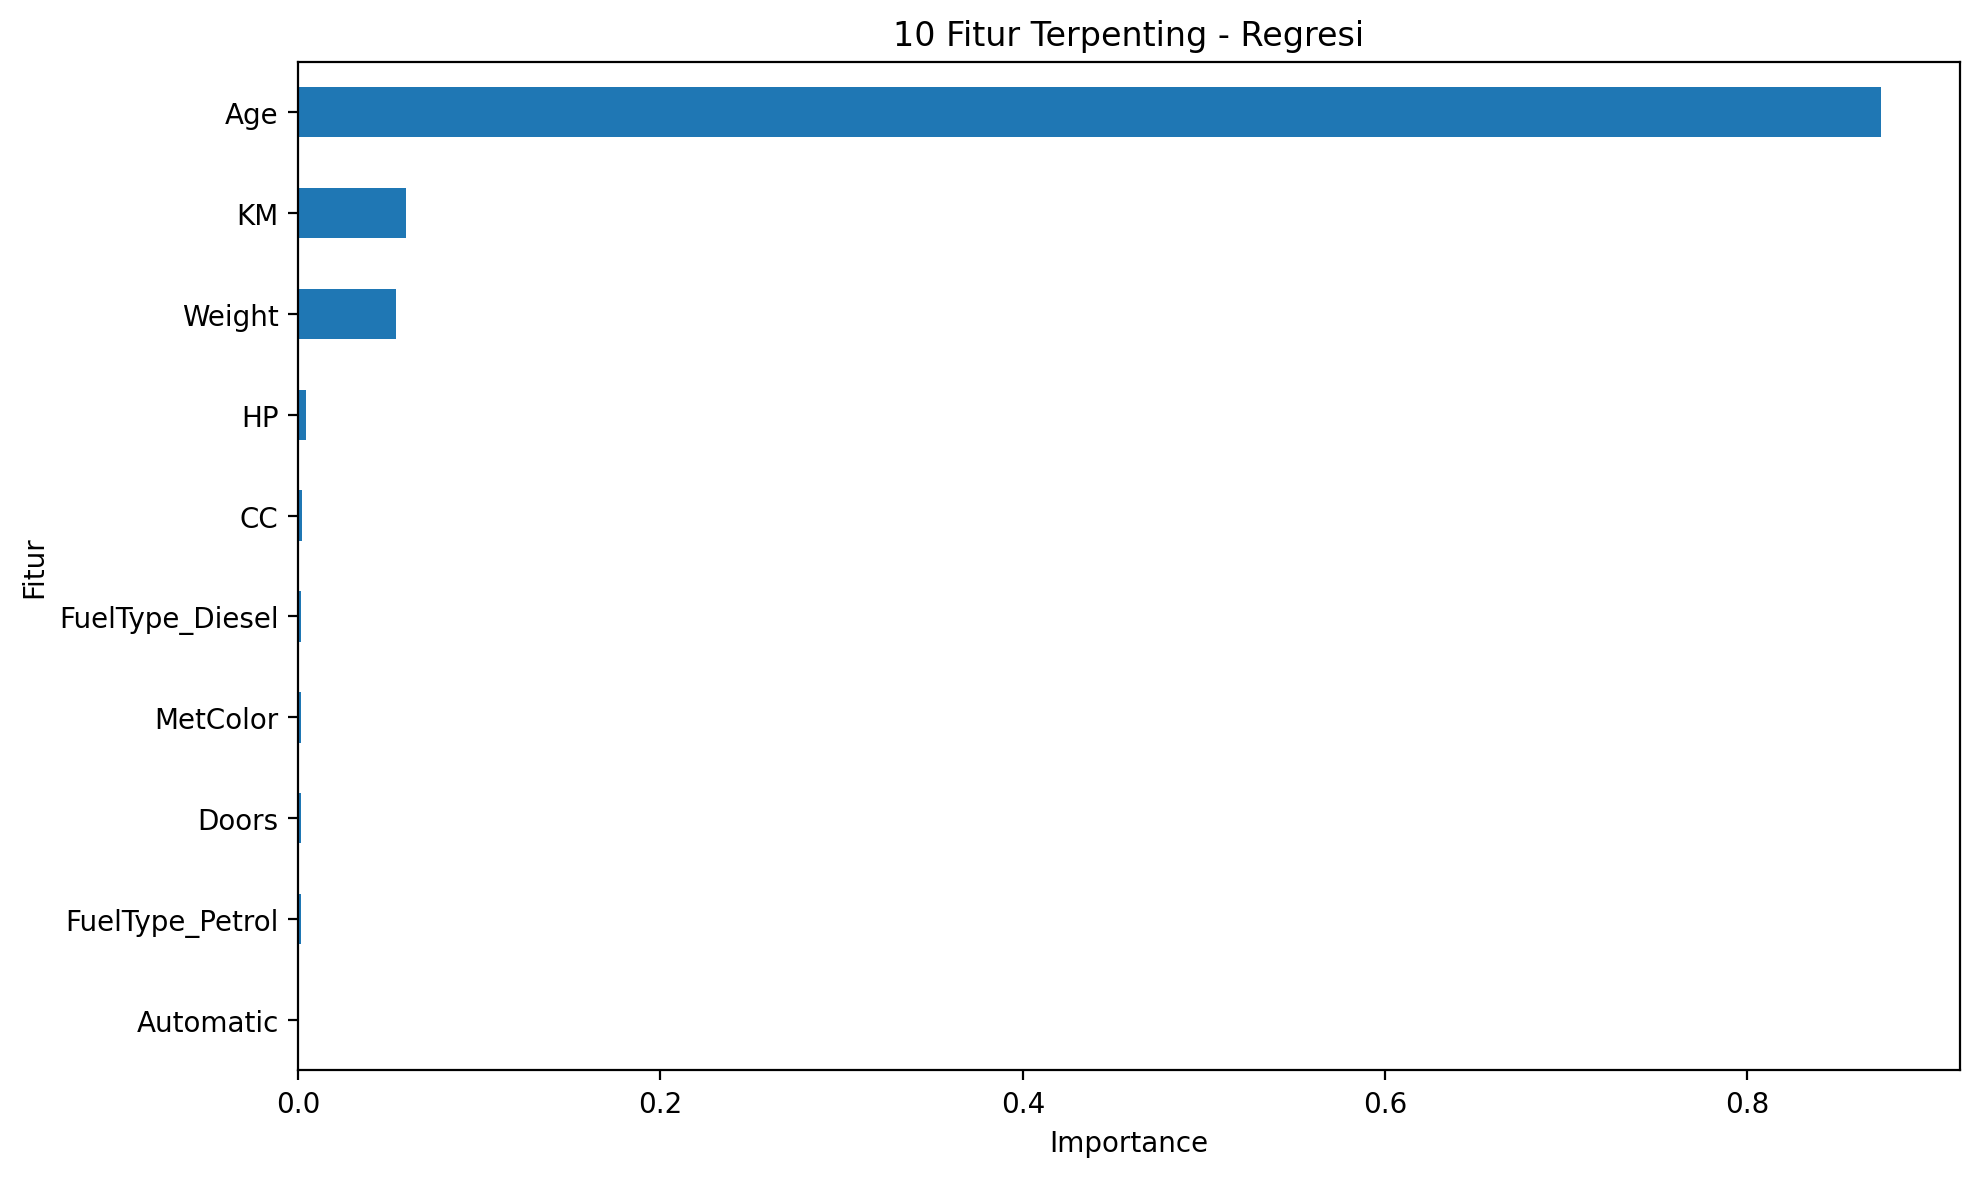

In [37]:
# Menampilkan 10 fitur terpenting
top_features = feature_importance.head(10).sort_values()

plt.figure(figsize=(10, 6))

top_features.plot(kind="barh")

plt.title("10 Fitur Terpenting - Regresi")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

## 9. Menyimpan Model
Model terbaik dan model Gradient Boosting disimpan ke file `.joblib` supaya bisa dimuat lagi tanpa melatih ulang.

In [38]:
joblib.dump(best_model, "best_model.joblib")
print("Model terbaik berhasil disimpan sebagai best_model.joblib")

joblib.dump(GBR, "gbr_model.joblib")
print("Model berhasil disimpan sebagai gbr_model.joblib")

Model terbaik berhasil disimpan sebagai best_model.joblib
Model berhasil disimpan sebagai gbr_model.joblib


## 10. Deployment
*Deployment* = membuat model bisa dipakai di luar notebook: menerima data mobil baru lalu mengembalikan prediksi harga.

**Alur di bagian ini**
1. **Simpan paket model**: bukan hanya model, tetapi juga `scaler`, urutan kolom, dan metadata. Tanpa `scaler`, data baru tidak bisa diubah ke skala yang dipahami model.
2. **`serving.py`**: fungsi prediksi yang menerima data *mentah*, melakukan standardisasi dan one-hot yang sama seperti training, lalu mengembalikan harga dalam satuan asli.
3. **Uji sebelum dipakai**: hasil fungsi ini harus sama dengan model di notebook (uji konsistensi).
4. **`app.py`**: API (FastAPI) dengan endpoint `/health` dan `/predict`. Setiap permintaan dicatat ke `prediction_log.csv` untuk bahan monitoring.

**File yang dihasilkan:** `model_bundle.joblib`, `model_metadata.json`, `serving.py`, `app.py`, `requirements.txt`.

In [39]:
# 21. DEPLOYMENT - MENYIMPAN PAKET MODEL (MODEL + PREPROCESSING + METADATA)
paket_model = {
    "model": best_model,
    "model_name": model_terbaik,
    "scaler": scaler,                              # StandardScaler yang dilatih di langkah 3
    "numeric_cols": numeric_cols,                  # urutan kolom saat scaler dilatih
    "idx_price": numeric_cols.index("Price"),      # posisi Price (untuk mengembalikan ke harga asli)
    "feature_columns": x_train.columns.tolist(),   # urutan kolom saat model dilatih
    "metrics_test_standar": hasil_regresi.loc[
        model_terbaik, ["MAE", "MSE", "RMSE", "R2"]
    ].round(4).to_dict(),
    "trained_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "sklearn_version": sklearn.__version__,
}

joblib.dump(paket_model, "model_bundle.joblib")

# Metadata yang bisa dibaca manusia (tanpa objek model/scaler)
metadata = {k: v for k, v in paket_model.items() if k not in ("model", "scaler")}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Paket model disimpan: model_bundle.joblib")
print("Metadata disimpan   : model_metadata.json")
print(json.dumps(metadata, indent=2))

Paket model disimpan: model_bundle.joblib
Metadata disimpan   : model_metadata.json
{
  "model_name": "Gradient Boosting",
  "numeric_cols": [
    "Price",
    "Age",
    "KM",
    "HP",
    "MetColor",
    "Automatic",
    "CC",
    "Doors",
    "Weight"
  ],
  "idx_price": 0,
  "feature_columns": [
    "Age",
    "KM",
    "HP",
    "MetColor",
    "Automatic",
    "CC",
    "Doors",
    "Weight",
    "FuelType_Diesel",
    "FuelType_Petrol"
  ],
  "metrics_test_standar": {
    "MAE": 0.3196,
    "MSE": 0.1708,
    "RMSE": 0.4132,
    "R2": 0.8332
  },
  "trained_at": "2026-10-17 08:08:48",
  "sklearn_version": "1.8.0"
}


In [40]:
%%writefile serving.py
"""Modul prediksi harga Toyota Corolla.
Dipakai oleh notebook DAN API supaya preprocessing-nya identik."""
import numpy as np
import pandas as pd

KOLOM_INPUT = ["Age", "KM", "FuelType", "HP", "MetColor", "Automatic", "CC", "Doors", "Weight"]
JENIS_BBM = ["CNG", "Diesel", "Petrol"]   # sesuai data training


def siapkan_fitur(data_baru, paket):
    """Data mentah mobil -> fitur siap model (skala & urutan kolom sama seperti training)."""
    if isinstance(data_baru, dict):
        data = pd.DataFrame([data_baru])
    else:
        data = pd.DataFrame(data_baru).copy()

    kurang = [k for k in KOLOM_INPUT if k not in data.columns]
    if kurang:
        raise ValueError(f"Kolom input kurang: {kurang}")

    if data[KOLOM_INPUT].isnull().any().any():
        raise ValueError("Input mengandung nilai kosong.")

    tidak_dikenal = set(data["FuelType"].unique()) - set(JENIS_BBM)
    if tidak_dikenal:
        raise ValueError(f"FuelType tidak dikenal: {sorted(tidak_dikenal)}. Pilihan: {JENIS_BBM}")

    scaler = paket["scaler"]
    fitur = pd.DataFrame(index=data.index)
    for i, kolom in enumerate(paket["numeric_cols"]):
        if kolom == "Price":
            continue   # target tidak ikut sebagai fitur
        fitur[kolom] = (data[kolom].astype(float) - scaler.mean_[i]) / scaler.scale_[i]

    dummies = pd.get_dummies(data["FuelType"], prefix="FuelType", dtype=int)
    fitur = pd.concat([fitur, dummies], axis=1)
    return fitur.reindex(columns=paket["feature_columns"], fill_value=0)


def prediksi_harga(data_baru, paket):
    """Mengembalikan prediksi dalam skala standar dan dalam satuan harga asli."""
    fitur = siapkan_fitur(data_baru, paket)
    pred_std = paket["model"].predict(fitur)

    scaler, ip = paket["scaler"], paket["idx_price"]
    harga = pred_std * scaler.scale_[ip] + scaler.mean_[ip]

    return pd.DataFrame(
        {"Prediksi (standar)": pred_std, "Prediksi Harga": np.round(harga, 0)},
        index=fitur.index,
    )

Writing serving.py


In [41]:
# 22. DEPLOYMENT - UJI SEBELUM DIPAKAI (SIMULASI "LOAD DARI DISK" SEPERTI SERVER)
importlib.invalidate_caches()
import serving
importlib.reload(serving)
from serving import prediksi_harga, KOLOM_INPUT

paket = joblib.load("model_bundle.joblib")

# Data mentah (sebelum IQR dan standardisasi) - indeks barisnya sama dengan x_test
raw = pd.read_csv("ToyotaCorolla.csv")
raw.columns = raw.columns.str.strip()

# Uji 1: konsistensi - hasil fungsi deployment harus sama dengan model di notebook
hasil_uji = prediksi_harga(raw.loc[x_test.index, KOLOM_INPUT], paket)
cocok = np.allclose(hasil_uji["Prediksi (standar)"].to_numpy(), best_model.predict(x_test))
print("Uji konsistensi preprocessing (harus True):", cocok)

# Uji 2: performa dalam satuan harga asli (bukan standar)
harga_aktual = raw.loc[x_test.index, "Price"]
BASELINE = {
    "MAE": float(mean_absolute_error(harga_aktual, hasil_uji["Prediksi Harga"])),
    "RMSE": float(np.sqrt(mean_squared_error(harga_aktual, hasil_uji["Prediksi Harga"]))),
    "R2": float(r2_score(harga_aktual, hasil_uji["Prediksi Harga"])),
}
print("\nBASELINE PERFORMA (data test, satuan harga asli)")
for k, v in BASELINE.items():
    print(f"  {k:5s}= {v:,.4f}")

perbandingan = pd.DataFrame({
    "Harga Aktual": harga_aktual,
    "Prediksi Harga": hasil_uji["Prediksi Harga"],
})
perbandingan["Selisih"] = perbandingan["Harga Aktual"] - perbandingan["Prediksi Harga"]
print("\nContoh 5 prediksi pada data test:")
display(perbandingan.head())

# Uji 3: prediksi mobil baru (input mentah, tanpa perlu standardisasi manual)
mobil_baru = {
    "Age": 30, "KM": 60000, "FuelType": "Petrol", "HP": 110,
    "MetColor": 1, "Automatic": 0, "CC": 1600, "Doors": 4, "Weight": 1050,
}
print("\nPrediksi mobil baru:")
display(prediksi_harga(mobil_baru, paket))

Uji konsistensi preprocessing (harus True): True

BASELINE PERFORMA (data test, satuan harga asli)
  MAE  = 740.1718
  RMSE = 956.8953
  R2   = 0.8332

Contoh 5 prediksi pada data test:


,Harga Aktual,Prediksi Harga,Selisih
1009,8900,9879.0,-979.0
1172,7750,7911.0,-161.0
572,10950,9939.0,1011.0
661,9750,9513.0,237.0
968,9950,9832.0,118.0



Prediksi mobil baru:


,Prediksi (standar),Prediksi Harga
0,1.970061,14616.0


In [42]:
# 23. DEPLOYMENT - REQUIREMENTS (VERSI LIBRARY HARUS SAMA SAAT MODEL DIMUAT)
with open("requirements.txt", "w") as f:
    f.write(
        f"pandas=={pd.__version__}\n"
        f"numpy=={np.__version__}\n"
        f"scikit-learn=={sklearn.__version__}\n"
        f"joblib=={joblib.__version__}\n"
        "fastapi\n"
        "uvicorn\n"
    )

print(open("requirements.txt").read())

pandas==3.0.2
numpy==2.4.4
scikit-learn==1.8.0
joblib==1.5.3
fastapi
uvicorn



In [43]:
%%writefile app.py
"""API prediksi harga Toyota Corolla.
Jalankan di terminal:  uvicorn app:app --reload
Dokumentasi otomatis:  http://127.0.0.1:8000/docs"""
import csv
from datetime import datetime
from pathlib import Path
from typing import Literal

import joblib
from fastapi import FastAPI
from pydantic import BaseModel, Field

from serving import KOLOM_INPUT, prediksi_harga

paket = joblib.load("model_bundle.joblib")
LOG_PREDIKSI = Path("prediction_log.csv")   # dipakai untuk monitoring

app = FastAPI(title="API Prediksi Harga Toyota Corolla", version="1.0")


class Mobil(BaseModel):
    Age: float = Field(..., ge=0, le=120, description="Umur mobil (bulan)")
    KM: float = Field(..., ge=0, le=500000, description="Jarak tempuh (km)")
    FuelType: Literal["CNG", "Diesel", "Petrol"]
    HP: float = Field(..., ge=40, le=300, description="Tenaga mesin (HP)")
    MetColor: int = Field(..., ge=0, le=1, description="Warna metalik: 0/1")
    Automatic: int = Field(..., ge=0, le=1, description="Transmisi otomatis: 0/1")
    CC: float = Field(..., ge=500, le=4000, description="Kapasitas mesin (cc)")
    Doors: int = Field(..., ge=2, le=5, description="Jumlah pintu")
    Weight: float = Field(..., ge=700, le=2500, description="Berat (kg)")


def catat_prediksi(data, harga):
    baris = {"waktu": datetime.now().isoformat(timespec="seconds"), **data, "prediksi_harga": harga}
    baru = not LOG_PREDIKSI.exists()
    with open(LOG_PREDIKSI, "a", newline="") as f:
        penulis = csv.DictWriter(f, fieldnames=list(baris.keys()))
        if baru:
            penulis.writeheader()
        penulis.writerow(baris)


@app.get("/health")
def health():
    return {
        "status": "ok",
        "model": paket["model_name"],
        "trained_at": paket["trained_at"],
        "sklearn_version": paket["sklearn_version"],
    }


@app.post("/predict")
def predict(mobil: Mobil):
    data = mobil.model_dump()
    hasil = prediksi_harga(data, paket)
    harga = float(hasil["Prediksi Harga"].iloc[0])
    catat_prediksi({k: data[k] for k in KOLOM_INPUT}, harga)
    return {"prediksi_harga": harga, "model": paket["model_name"]}

Writing app.py


In [44]:
# 24. DEPLOYMENT - UJI API TANPA MENJALANKAN SERVER (butuh: pip install fastapi httpx)
Path("prediction_log.csv").unlink(missing_ok=True)   # hapus log lama agar demo bersih

try:
    from fastapi.testclient import TestClient
    import app as api_app
    importlib.reload(api_app)
except ImportError as e:
    print("Lewati uji API, pasang dulu: pip install fastapi httpx uvicorn ->", e)
else:
    client = TestClient(api_app.app)

    print("GET /health ->", client.get("/health").json())

    r = client.post("/predict", json=mobil_baru)
    print("POST /predict ->", r.status_code, r.json())

    # Input tidak valid harus ditolak (status 422)
    salah = {**mobil_baru, "FuelType": "Hybrid"}
    r = client.post("/predict", json=salah)
    print("POST /predict (FuelType salah) ->", r.status_code)

    # Simulasi trafik produksi: kirim seluruh data test ke API
    data_trafik = raw.loc[x_test.index, KOLOM_INPUT].to_dict(orient="records")
    kode = [client.post("/predict", json=d).status_code for d in data_trafik]
    print(f"Trafik simulasi: {len(kode)} request, sukses={kode.count(200)}")

/usr/local/lib/python3.12/dist-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


GET /health -> {'status': 'ok', 'model': 'Gradient Boosting', 'trained_at': '2026-10-17 08:08:48', 'sklearn_version': '1.8.0'}
POST /predict -> 200 {'prediksi_harga': 14616.0, 'model': 'Gradient Boosting'}
POST /predict (FuelType salah) -> 422


Trafik simulasi: 227 request, sukses=227


**Menjalankan API sungguhan (di terminal, bukan di notebook):** buka terminal di folder yang sama dengan file ini, lalu jalankan
```
uvicorn app:app --reload
```
Setelah itu buka `http://127.0.0.1:8000/docs` untuk mencoba `/predict` lewat tampilan interaktif.
Versi library saat memuat model harus sama dengan saat melatih (lihat `requirements.txt`), karena `model_bundle.joblib` adalah file pickle.

## 11. Monitoring
*Monitoring* = memantau apakah model masih layak dipakai setelah berjalan di dunia nyata. Model bisa memburuk karena dua hal:

| Masalah | Artinya | Cara memantau |
|---|---|---|
| **Data drift** | Data masuk berbeda dari data training (mis. mobil makin tua) | **PSI** dan uji **KS** per fitur, tidak perlu harga asli |
| **Penurunan performa** (*concept drift*) | Hubungan fitur ke harga berubah (mis. harga pasar turun) | Hitung ulang MAE/RMSE/R2 pada batch yang harga aslinya diketahui, bandingkan dengan baseline |

**Cara membaca PSI:** di bawah 0,10 = `AMAN`, 0,10 sampai 0,25 = `WASPADA`, 0,25 ke atas = `DRIFT`.
**Aturan alert performa:** `ALERT` jika RMSE naik lebih dari 25% atau R2 turun lebih dari 0,10 dibanding baseline.

> Skenario "batch bergeser" dan "harga pasar turun 20%" di bawah adalah **simulasi** untuk memperlihatkan bahwa alarm bekerja. Di penggunaan nyata, data batch berasal dari `prediction_log.csv` dan harga aslinya dari transaksi.

In [45]:
# 25. MONITORING - DETEKSI DATA DRIFT (DATA BARU VS DATA TRAINING)
def hitung_psi(acuan, baru, bins=10, eps=1e-4):
    """Population Stability Index. <0.10 aman | 0.10-0.25 waspada | >=0.25 drift."""
    acuan, baru = np.asarray(acuan), np.asarray(baru)
    if len(np.unique(acuan)) <= bins:            # fitur kategorikal / biner
        kategori = np.unique(np.concatenate([acuan, baru]))
        p = np.array([(acuan == k).mean() for k in kategori])
        q = np.array([(baru == k).mean() for k in kategori])
    else:                                        # fitur numerik -> bin berdasarkan kuantil data training
        batas = np.unique(np.quantile(acuan, np.linspace(0, 1, bins + 1)))
        batas[0], batas[-1] = -np.inf, np.inf
        p = np.histogram(acuan, bins=batas)[0] / len(acuan)
        q = np.histogram(baru, bins=batas)[0] / len(baru)
    p, q = np.clip(p, eps, None), np.clip(q, eps, None)
    return float(np.sum((q - p) * np.log(q / p)))


def laporan_drift(data_acuan, data_baru, fitur=KOLOM_INPUT, min_data=100):
    if len(data_baru) < min_data:
        print(f"PERINGATAN: data baru hanya {len(data_baru)} baris (< {min_data}), PSI kurang andal.")
    baris = []
    for kol in fitur:
        psi = hitung_psi(data_acuan[kol], data_baru[kol])
        numerik = kol != "FuelType"
        baris.append({
            "Fitur": kol,
            "PSI": round(psi, 4),
            "KS p-value": round(ks_2samp(data_acuan[kol], data_baru[kol]).pvalue, 4) if numerik else np.nan,
            "Rata2 Training": round(float(data_acuan[kol].mean()), 2) if numerik else np.nan,
            "Rata2 Baru": round(float(data_baru[kol].mean()), 2) if numerik else np.nan,
            "Status": "DRIFT" if psi >= 0.25 else ("WASPADA" if psi >= 0.10 else "AMAN"),
        })
    return pd.DataFrame(baris).set_index("Fitur")


# Data acuan = data mentah yang dipakai untuk training
data_acuan = raw.loc[x_train.index, KOLOM_INPUT]

# Skenario 1: batch normal (data test, distribusinya sama dengan training)
batch_normal = raw.loc[x_test.index, KOLOM_INPUT]

# Skenario 2 (SIMULASI): pasar bergeser -> mobil lebih tua, lebih jauh jalan, lebih banyak diesel
batch_drift = batch_normal.copy()
batch_drift["Age"] = batch_drift["Age"] + 15
batch_drift["KM"] = batch_drift["KM"] * 1.5
idx_diesel = batch_drift.sample(frac=0.3, random_state=42).index
batch_drift.loc[idx_diesel, "FuelType"] = "Diesel"

drift_normal = laporan_drift(data_acuan, batch_normal)
drift_geser = laporan_drift(data_acuan, batch_drift)

print("LAPORAN DRIFT - BATCH NORMAL")
display(drift_normal)
print("\nLAPORAN DRIFT - BATCH BERGESER (simulasi)")
display(drift_geser)

LAPORAN DRIFT - BATCH NORMAL


,PSI,KS p-value,Rata2 Training,Rata2 Baru,Status
Fitur,,,,,
Age,0.0458,0.4154,59.00,57.46,AMAN
KM,0.0253,0.5868,66136.70,67235.04,AMAN
FuelType,0.0264,NaN,NaN,NaN,AMAN
HP,0.0275,0.9978,102.91,101.82,AMAN
MetColor,0.0065,0.9466,0.69,0.65,AMAN
Automatic,0.0000,1.0000,0.00,0.00,AMAN
CC,0.0480,0.9992,1520.31,1528.33,AMAN
Doors,0.0032,1.0000,4.02,4.00,AMAN
Weight,0.0501,0.9995,1056.68,1057.43,AMAN



LAPORAN DRIFT - BATCH BERGESER (simulasi)


,PSI,KS p-value,Rata2 Training,Rata2 Baru,Status
Fitur,,,,,
Age,0.8711,0.0000,59.00,72.46,DRIFT
KM,0.8568,0.0000,66136.70,100852.57,DRIFT
FuelType,1.0359,NaN,NaN,NaN,DRIFT
HP,0.0275,0.9978,102.91,101.82,AMAN
MetColor,0.0065,0.9466,0.69,0.65,AMAN
Automatic,0.0000,1.0000,0.00,0.00,AMAN
CC,0.0480,0.9992,1520.31,1528.33,AMAN
Doors,0.0032,1.0000,4.02,4.00,AMAN
Weight,0.0501,0.9995,1056.68,1057.43,AMAN


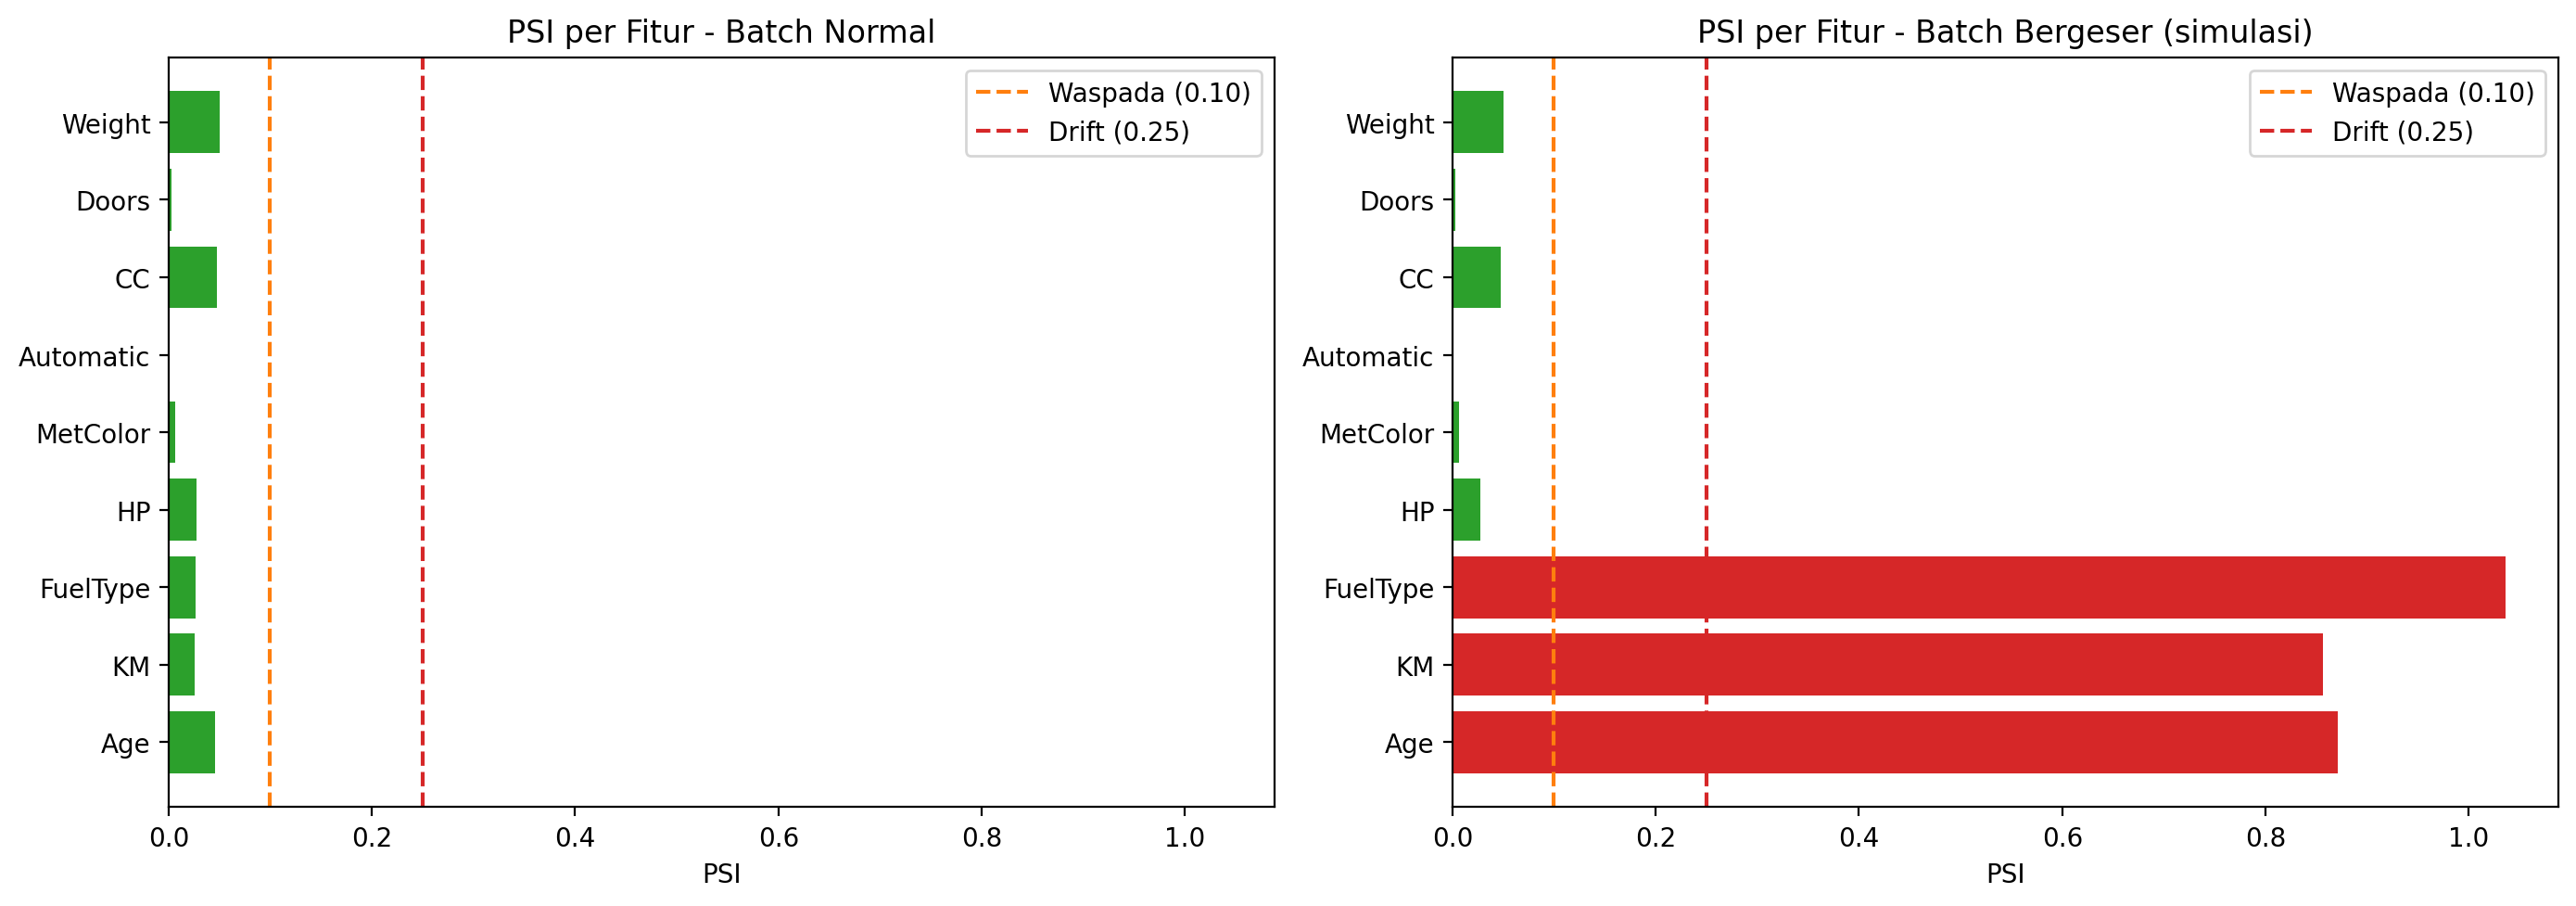

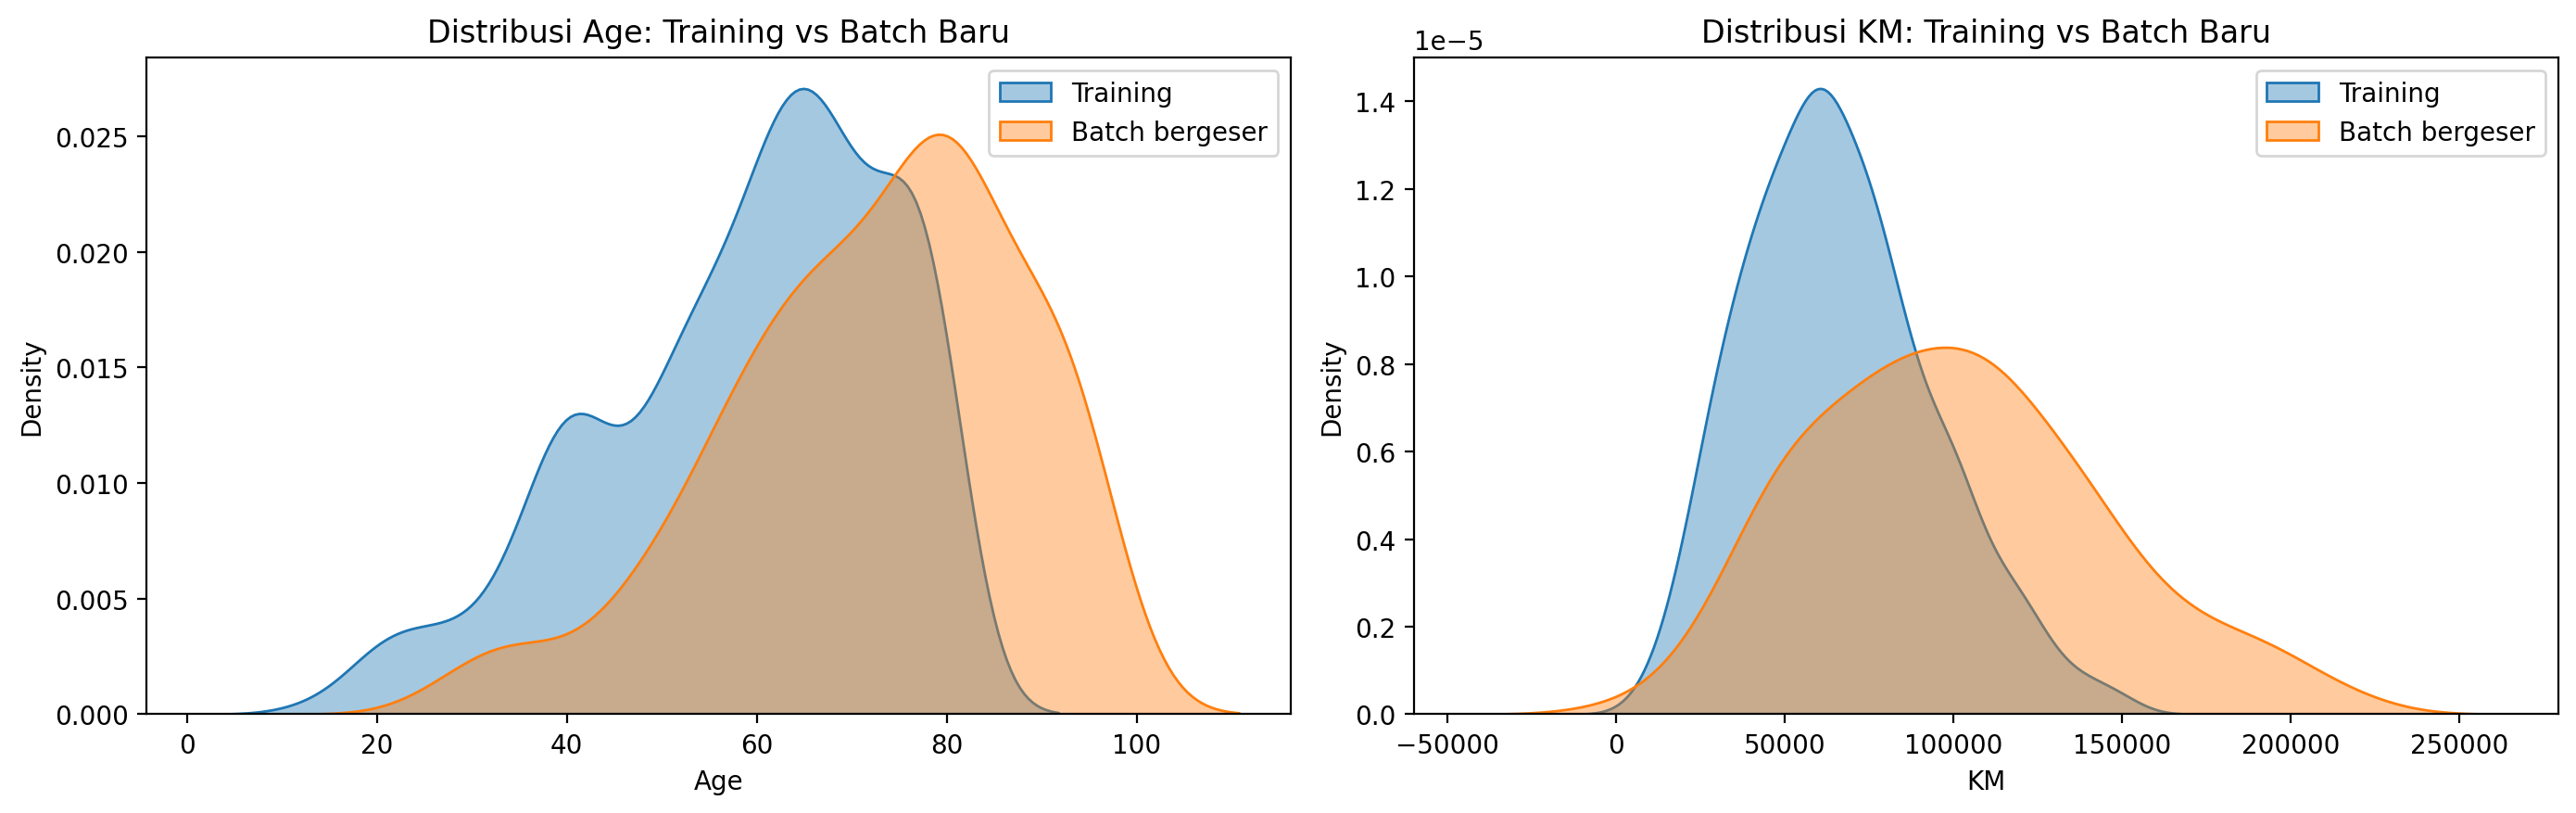

In [46]:
# 26. MONITORING - VISUALISASI DRIFT
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax, (judul, rpt) in zip(axes, [("Batch Normal", drift_normal), ("Batch Bergeser (simulasi)", drift_geser)]):
    warna = rpt["Status"].map({"AMAN": "tab:green", "WASPADA": "tab:orange", "DRIFT": "tab:red"})
    ax.barh(rpt.index, rpt["PSI"], color=warna)
    ax.axvline(0.10, linestyle="--", color="tab:orange", label="Waspada (0.10)")
    ax.axvline(0.25, linestyle="--", color="tab:red", label="Drift (0.25)")
    ax.set_title(f"PSI per Fitur - {judul}")
    ax.set_xlabel("PSI")
    ax.legend()

plt.tight_layout()
plt.show()

# Perbandingan distribusi fitur yang bergeser
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, kol in zip(axes, ["Age", "KM"]):
    sns.kdeplot(data_acuan[kol], ax=ax, label="Training", fill=True, alpha=0.4)
    sns.kdeplot(batch_drift[kol], ax=ax, label="Batch bergeser", fill=True, alpha=0.4)
    ax.set_title(f"Distribusi {kol}: Training vs Batch Baru")
    ax.legend()
plt.tight_layout()
plt.show()

In [47]:
# 27. MONITORING - PERFORMA MODEL DARI WAKTU KE WAKTU (+ LOG DAN ALERT)
LOG_PERFORMA = Path("monitoring_log.csv")
LOG_PERFORMA.unlink(missing_ok=True)   # hapus log lama agar demo bersih (di produksi JANGAN dihapus)

AMBANG_RMSE_NAIK = 0.25   # alert jika RMSE naik > 25% dari baseline
AMBANG_R2_TURUN = 0.10    # alert jika R2 turun > 0.10 dari baseline


def evaluasi_batch(nama_batch, data_mentah, harga_aktual, paket):
    """Evaluasi satu batch yang harga aslinya sudah diketahui, catat ke log, beri status."""
    pred = prediksi_harga(data_mentah, paket)["Prediksi Harga"].to_numpy()
    hasil = {
        "waktu": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "batch": nama_batch,
        "n_data": len(pred),
        "MAE": mean_absolute_error(harga_aktual, pred),
        "RMSE": np.sqrt(mean_squared_error(harga_aktual, pred)),
        "R2": r2_score(harga_aktual, pred),
    }
    hasil["RMSE naik (%)"] = (hasil["RMSE"] / BASELINE["RMSE"] - 1) * 100
    hasil["R2 turun"] = BASELINE["R2"] - hasil["R2"]
    alert = (hasil["RMSE naik (%)"] > AMBANG_RMSE_NAIK * 100) or (hasil["R2 turun"] > AMBANG_R2_TURUN)
    hasil["status"] = "ALERT" if alert else "AMAN"

    pd.DataFrame([hasil]).to_csv(LOG_PERFORMA, mode="a", header=not LOG_PERFORMA.exists(), index=False)
    return hasil


# Simulasi: 2 batch normal + 1 batch dengan harga pasar turun 20% (concept drift)
idx_batch = np.array_split(x_test.index.to_numpy(), 2)

evaluasi_batch("minggu_1 (normal)", raw.loc[idx_batch[0], KOLOM_INPUT], raw.loc[idx_batch[0], "Price"], paket)
evaluasi_batch("minggu_2 (normal)", raw.loc[idx_batch[1], KOLOM_INPUT], raw.loc[idx_batch[1], "Price"], paket)
evaluasi_batch("minggu_3 (harga pasar turun 20%)", batch_normal, raw.loc[x_test.index, "Price"] * 0.8, paket)

log_performa = pd.read_csv(LOG_PERFORMA)
print("BASELINE:", {k: round(v, 4) for k, v in BASELINE.items()})
print("\nLOG MONITORING PERFORMA")
display(log_performa.round(4))

BASELINE: {'MAE': 740.1718, 'RMSE': 956.8953, 'R2': 0.8332}

LOG MONITORING PERFORMA


,waktu,batch,n_data,MAE,RMSE,R2,RMSE naik (%),R2 turun,status
0,2026-10-17 08:08:51,minggu_1 (normal),114,714.6140,915.7574,0.8252,-4.2991,0.0080,AMAN
1,2026-10-17 08:08:51,minggu_2 (normal),113,765.9558,996.6781,0.8394,4.1575,-0.0062,AMAN
2,2026-10-17 08:08:51,minggu_3 (harga pasar turun 20%),227,2031.2996,2209.1593,-0.3890,130.8674,1.2222,ALERT


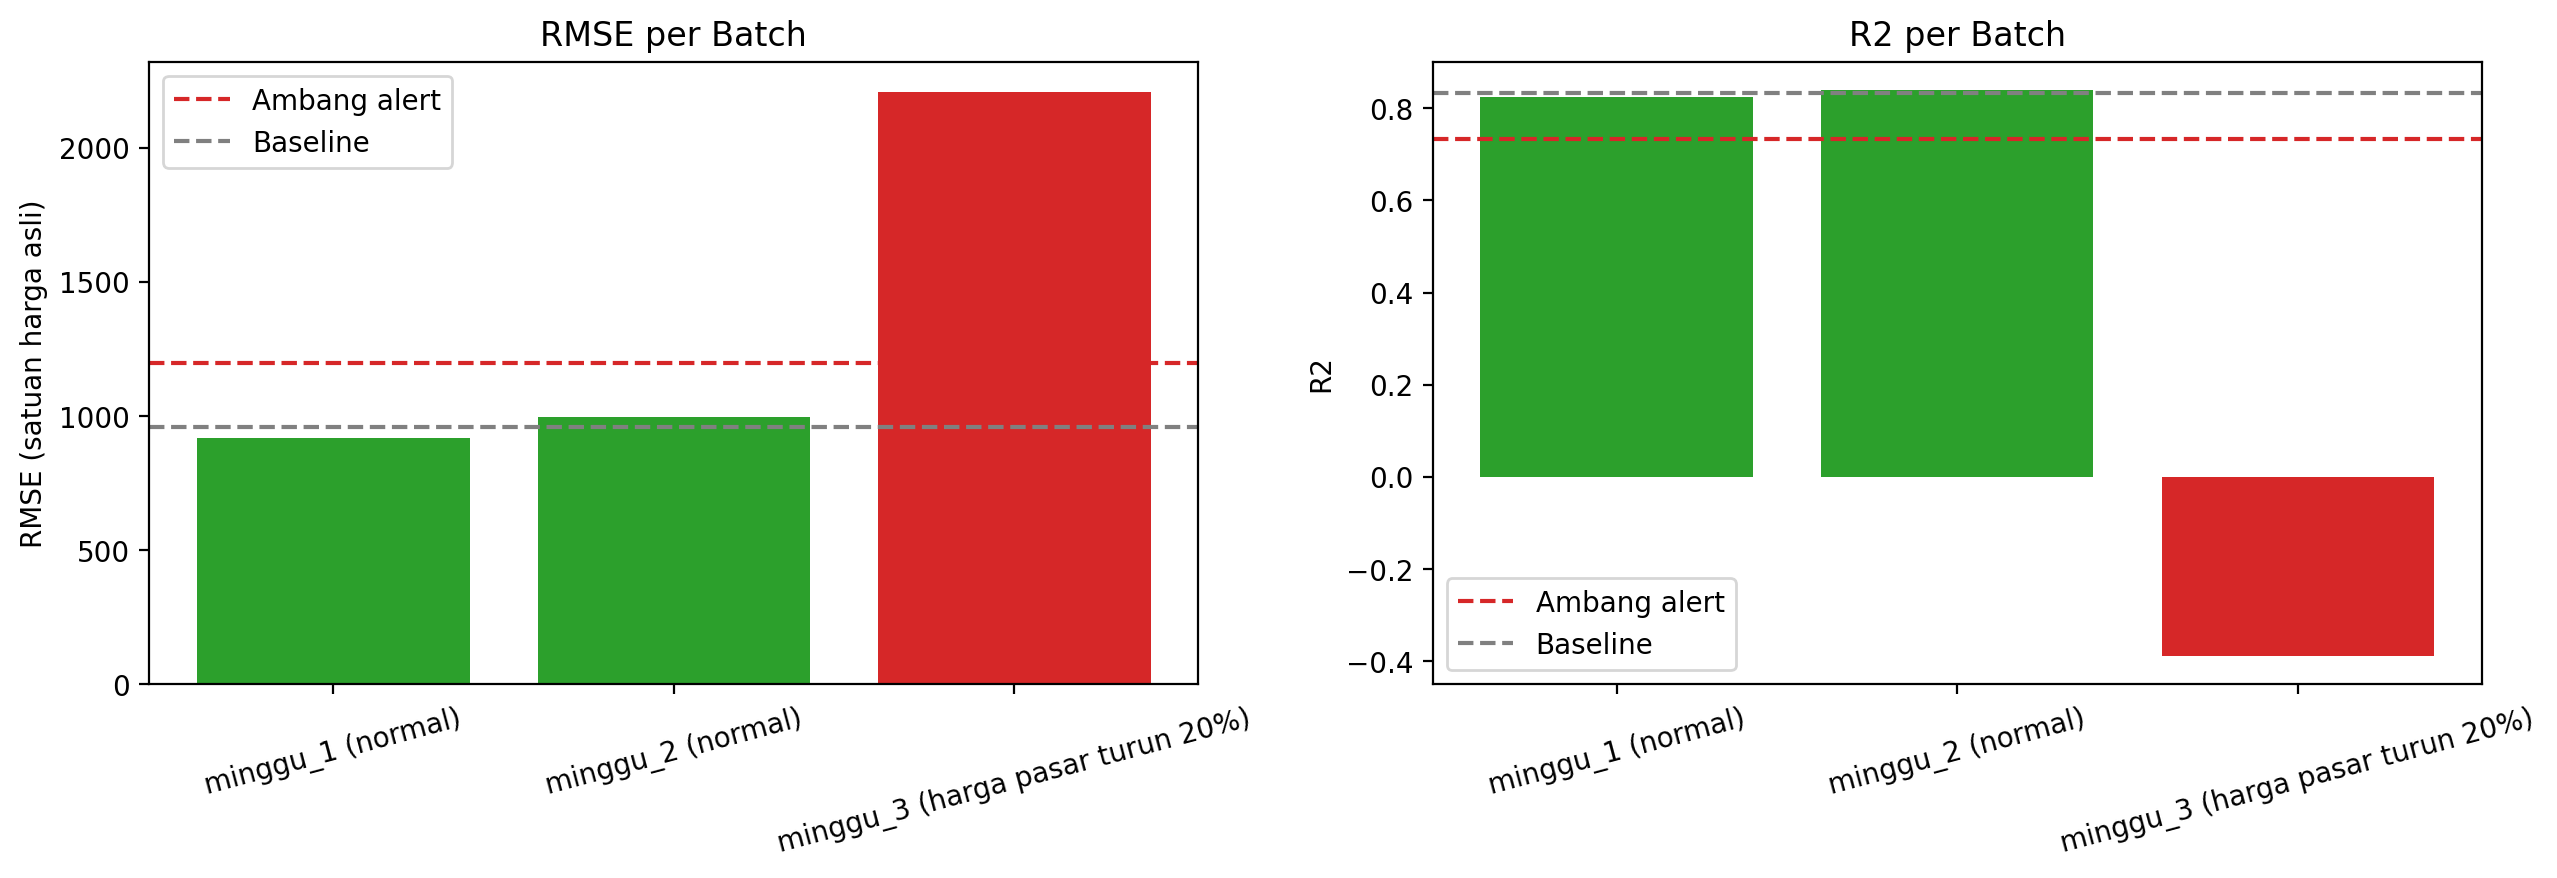

In [48]:
# 28. MONITORING - TREN PERFORMA
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

warna = log_performa["status"].map({"AMAN": "tab:green", "ALERT": "tab:red"})

axes[0].bar(log_performa["batch"], log_performa["RMSE"], color=warna)
axes[0].axhline(BASELINE["RMSE"] * (1 + AMBANG_RMSE_NAIK), linestyle="--", color="tab:red", label="Ambang alert")
axes[0].axhline(BASELINE["RMSE"], linestyle="--", color="gray", label="Baseline")
axes[0].set_title("RMSE per Batch")
axes[0].set_ylabel("RMSE (satuan harga asli)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend()

axes[1].bar(log_performa["batch"], log_performa["R2"], color=warna)
axes[1].axhline(BASELINE["R2"] - AMBANG_R2_TURUN, linestyle="--", color="tab:red", label="Ambang alert")
axes[1].axhline(BASELINE["R2"], linestyle="--", color="gray", label="Baseline")
axes[1].set_title("R2 per Batch")
axes[1].set_ylabel("R2")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend()

plt.tight_layout()
plt.show()

In [49]:
# 29. MONITORING - DATA PRODUKSI DARI LOG API (prediction_log.csv)
if Path("prediction_log.csv").exists():
    log_api = pd.read_csv("prediction_log.csv")
    print("Jumlah request tercatat:", len(log_api))
    print("Prediksi harga -> rata-rata: %.0f | min: %.0f | max: %.0f" % (
        log_api["prediksi_harga"].mean(), log_api["prediksi_harga"].min(), log_api["prediksi_harga"].max()))

    print("\nLAPORAN DRIFT - DATA DARI LOG API")
    display(laporan_drift(data_acuan, log_api[KOLOM_INPUT]))
else:
    print("prediction_log.csv belum ada. Jalankan API (atau sel 24) dan kirim beberapa request dulu.")

Jumlah request tercatat: 228
Prediksi harga -> rata-rata: 10198 | min: 6277 | max: 16550

LAPORAN DRIFT - DATA DARI LOG API


,PSI,KS p-value,Rata2 Training,Rata2 Baru,Status
Fitur,,,,,
Age,0.0466,0.3749,59.00,57.34,AMAN
KM,0.0258,0.6260,66136.70,67203.31,AMAN
FuelType,0.0262,NaN,NaN,NaN,AMAN
HP,0.0271,0.9987,102.91,101.86,AMAN
MetColor,0.0059,0.9614,0.69,0.65,AMAN
Automatic,0.0000,1.0000,0.00,0.00,AMAN
CC,0.0475,0.9993,1520.31,1528.64,AMAN
Doors,0.0035,1.0000,4.02,4.00,AMAN
Weight,0.0489,0.9998,1056.68,1057.40,AMAN


## 12. Ringkasan dan Catatan

In [50]:
# 30. RINGKASAN STATUS DEPLOYMENT DAN MONITORING
berkas = ["model_bundle.joblib", "model_metadata.json", "serving.py", "app.py",
          "requirements.txt", "monitoring_log.csv", "prediction_log.csv"]

print("BERKAS DEPLOYMENT & MONITORING")
for b in berkas:
    print(f"  [{'ADA' if Path(b).exists() else '---'}] {b}")

print("\nSTATUS TERAKHIR")
print("  Drift data (batch normal)  :", drift_normal["Status"].value_counts().to_dict())
print("  Drift data (batch bergeser):", drift_geser["Status"].value_counts().to_dict())
print("  Performa batch terakhir    :", log_performa.iloc[-1]["batch"], "->", log_performa.iloc[-1]["status"])

BERKAS DEPLOYMENT & MONITORING
  [ADA] model_bundle.joblib
  [ADA] model_metadata.json
  [ADA] serving.py
  [ADA] app.py
  [ADA] requirements.txt
  [ADA] monitoring_log.csv
  [ADA] prediction_log.csv

STATUS TERAKHIR
  Drift data (batch normal)  : {'AMAN': 9}
  Drift data (batch bergeser): {'AMAN': 6, 'DRIFT': 3}
  Performa batch terakhir    : minggu_3 (harga pasar turun 20%) -> ALERT


### Catatan penting
- **Satuan error:** MAE/RMSE di bagian 7 dalam satuan simpangan baku karena `Price` distandardisasi. Di bagian 10 (uji deployment) error dihitung ulang dalam satuan harga asli.
- **Mobil otomatis:** filter IQR membuang semua mobil `Automatic`, jadi model ini tidak memakai informasi transmisi. Jika mobil otomatis mulai masuk saat dipakai, monitoring akan menandai fitur `Automatic` sebagai `DRIFT`.
- **Standardisasi sebelum split:** `StandardScaler` dilatih pada seluruh data sebelum dibagi training/testing, sehingga ada kebocoran data ringan. Praktik yang lebih ketat: bagi data dulu, lalu fit scaler hanya pada data training.
- **LARS:** dengan `n_nonzero_coefs=1` hanya satu fitur yang dipakai, jadi wajar jika paling lemah.
- **Langkah lanjutan jika model memburuk:** latih ulang dengan data terbaru, lalu simpan ulang paket model (bagian 10).